In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize
import plotly.graph_objects as go
pd.set_option("display.max_columns",None)
import statsmodels.api as sm
import seaborn as sns
from scipy.linalg import fractional_matrix_power
pd.options.display.float_format = '{:.4f}'.format

from matplotlib.ticker import NullFormatter

import ipywidgets as widgets
from rich.console import Console
from rich.text import Text
from rich.table import Table
import pyxirr
from pandas.tseries.offsets import DateOffset
from itertools import takewhile
console = Console()

In [40]:
all_sheets = pd.read_excel("Sample_Portfolio.xlsm",sheet_name=None)

data = all_sheets["Portfolio"]
mev = all_sheets["Macroeconomic variable"]
fed_funds_rate = all_sheets["FEDFUNDS"] 
all_sheets.keys()

dict_keys(['Portfolio', 'UNRATE', 'Macroeconomic variable', 'FEDFUNDS'])

In [41]:
console.print(f"Raw Data dimension : {data.shape}", style="bold")
data.head()

Raw Data dimension : (1500, 16)

,Customer_ID,Segment,Sector,Sanction_Amount (in USD),Outstanding_Balance,Type_of_Loan,Tenure,Maturity_Date,Loan_Duration_Flag,Sanction_Date,Origination_Rating,Origination_Interest_Rate,Secured_Unsecured_Flag,Collateral_Type,Collateral_Value,Reporting_Date
0,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2025-12-31
1,CUST000002HF,SME,F&B,3741382,2893456.0100,Amortising,240,2031-04-30,Long Term,2011-04-01,BBB,0.0519,Secured,Inventory,5472041.6300,2025-12-31
2,CUST000003TR,Retail,Mortgage,282233,233123.6400,Amortising,342,2050-05-31,Long Term,2021-11-08,B,0.0855,Secured,Real Estate,365790.1400,2025-12-31
3,CUST000004XC,Retail,Personal Loan,47946,41819.1600,Amortising,222,2040-12-31,Long Term,2022-06-21,BBB,0.0531,Unsecured,NaN,0.0000,2025-12-31
4,CUST000005KA,Retail,Credit Card,19029,18988.4800,Revolving,240,2036-12-31,Long Term,2016-12-09,BBB,0.0421,Unsecured,NaN,0.0000,2025-12-31


In [4]:
# Making sure the dates are in a specific format:

data["Maturity_Date"] = pd.to_datetime(data["Maturity_Date"], format ="%d-%m-%Y")
data["Sanction_Date"] = pd.to_datetime(data["Sanction_Date"], format ="%d-%m-%Y")
data["Reporting_Date"] = pd.to_datetime(data["Reporting_Date"], format ="%d-%m-%Y")

# 2. Assign the reporting date using pd.to_datetime (NOT datetime.date)
data["Reporting Date"] = pd.to_datetime("2025-12-31") # The last reporting date

# 3. Calculate MOB accurately by calculating the difference in months
data["MOB"] = ((data["Reporting Date"].dt.year - data["Sanction_Date"].dt.year) * 12) + (data["Reporting Date"].dt.month - data["Sanction_Date"].dt.month)

Total borrowers in the raw portfolio: 1500

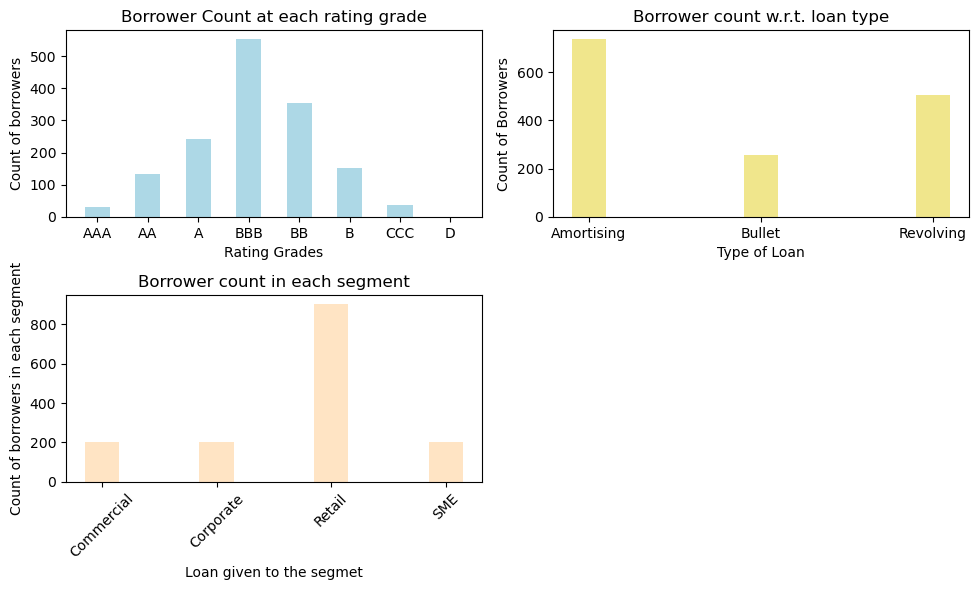

,Original_Rating_dist
Origination_Rating,
AAA,32
AA,132
A,241
BBB,553
BB,354
B,152
CCC,36
D,0


In [5]:
# Origination Rating distribution plot :

# 1 :
#rating_dist = pd.DataFrame(data.groupby(data["Origination_Rating"])["Customer_ID"].count()).reset_index()
rating_order = ["AAA","AA","A","BBB","BB","B","CCC","D"]

rating_dist = data["Origination_Rating"].value_counts().reindex(rating_order, fill_value=0)

rating_dist = pd.DataFrame(rating_dist).rename(columns={"count":"Original_Rating_dist"})

#rating_dist["Origination_Rating"] = pd.Categorical(rating_dist["Origination_Rating"],categories=rating_order, ordered = True)
#rating_dist = rating_dist.sort_values("Origination_Rating").reset_index(drop=True)

# 2 :
loan_type = pd.DataFrame(data.groupby(data["Type_of_Loan"])["Customer_ID"].count()).reset_index()

# 3 :
segment_type = pd.DataFrame(data.groupby(data["Segment"])["Customer_ID"].count()).reset_index()

total = rating_dist["Original_Rating_dist"].sum(axis=0)

#4 : Plots : 

fig, ax = plt.subplots(nrows=2,ncols=2, figsize=(10,6))
ax[0,0].bar(rating_dist.index,rating_dist["Original_Rating_dist"],width=0.5,color="lightblue",)
ax[0,0].set_xlabel("Rating Grades")
ax[0,0].set_ylabel("Count of borrowers")
ax[0,0].set_title("Borrower Count at each rating grade")

ax[0,1].bar(loan_type["Type_of_Loan"],loan_type["Customer_ID"], width=0.2,color="khaki")
ax[0,1].set_xlabel("Type of Loan")
ax[0,1].set_ylabel("Count of Borrowers")
ax[0,1].set_title("Borrower count w.r.t. loan type")

ax[1,0].bar(segment_type["Segment"],segment_type["Customer_ID"],color="bisque",width=0.3)
ax[1,0].set_xlabel("Loan given to the segmet")
ax[1,0].set_ylabel("Count of borrowers in each segment")
ax[1,0].set_title("Borrower count in each segment")
ax[1,0].tick_params(axis="x",labelrotation =45)
plt.tight_layout()

ax[1,1].set_visible(False)
console.print(f"Total borrowers in the raw portfolio: {total}", style="bold")
plt.show()
rating_dist

 Total number of borrowers after filtering: 1281

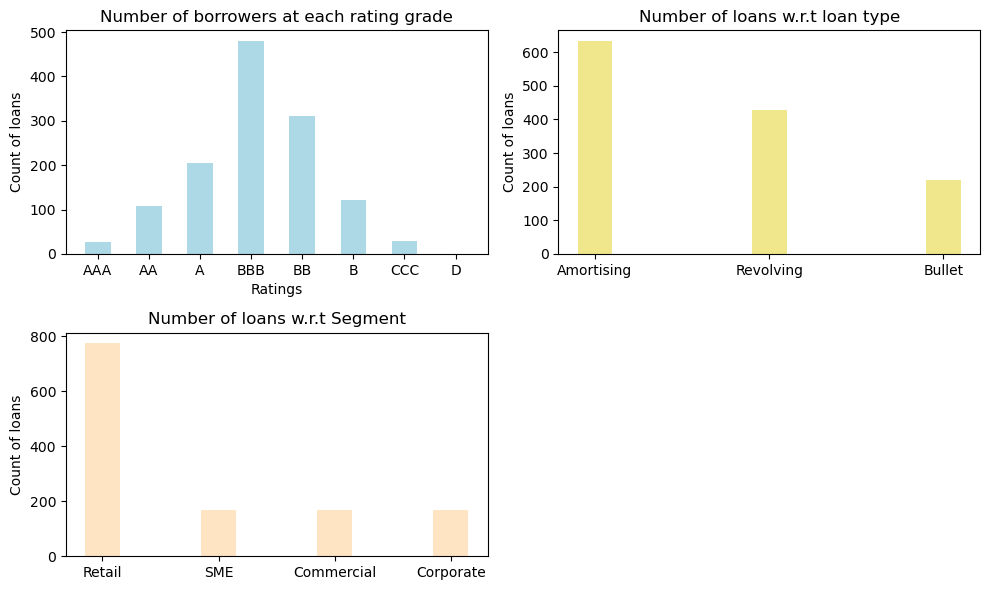

Customer_ID
Type_of_Loan Segment                
Amortising   Commercial           62
             Corporate            58
             Retail              463
             SME                  50
Bullet       Commercial           41
             Corporate            52
             Retail               66
             SME                  61
Revolving    Commercial           65
             Corporate            58
             Retail              246
             SME                  59

Total : 1281

In [6]:
# Filtering the Data to only consider those loans that are active on the Sanction Date : 
filtered_data = data[(data["Sanction_Date"]<= "2023-03-31")]
filtered_data = filtered_data[(filtered_data["Maturity_Date"]>"2023-03-31") | (filtered_data["Type_of_Loan"] == "Revolving")]

rating_order = ["AAA","AA","A","BBB","BB","B","CCC","D"]
reporting_date = pd.to_datetime("2023-03-31")


rating_trimmed = filtered_data["Origination_Rating"].value_counts().reindex(rating_order, fill_value=0)
rating_trimmed =pd.DataFrame(rating_trimmed)
rating_trimmed

loan_type_count = pd.DataFrame(filtered_data["Type_of_Loan"].value_counts())
segment_count = pd.DataFrame(filtered_data["Segment"].value_counts())

fig, ax = plt.subplots(nrows=2,ncols=2, figsize=(10,6))
console.print(f" Total number of borrowers after filtering: {rating_trimmed['count'].sum()}\n",style="Bold")
ax[0,0].bar(rating_trimmed.index,rating_trimmed["count"],width=0.5,color="lightblue")
ax[0,0].set_xlabel("Ratings")
ax[0,0].set_ylabel("Count of loans")
ax[0,0].set_title("Number of borrowers at each rating grade")

ax[0,1].bar(loan_type_count.index, loan_type_count["count"], width = 0.2, color= "khaki")
ax[0,1].set_label("Type of Loan")
ax[0,1].set_ylabel("Count of loans")
ax[0,1].set_title("Number of loans w.r.t loan type")

ax[1,0].bar(segment_count.index, segment_count["count"], width = 0.3, color= "bisque")
ax[1,0].set_label("Segment Type")
ax[1,0].set_ylabel("Count of loans")
ax[1,0].set_title("Number of loans w.r.t Segment")

ax[1,1].set_visible(False)
plt.tight_layout()
plt.show()
summ = pd.DataFrame(filtered_data.groupby(["Type_of_Loan","Segment"])["Customer_ID"].count())
display(summ)
console.print(f"Total : {summ['Customer_ID'].sum()}",style="bold")

In [7]:
# Creating a copy of the original dataset and forecasting the whole dataset for the next 2 years on a quarterly basis, from Q1 2023 - Q4 2025.

forecasting_data = filtered_data.copy()

forecasting_data["Sanction_Date"] = pd.to_datetime(forecasting_data["Sanction_Date"], dayfirst=True)
forecasting_data["Maturity_Date"] = pd.to_datetime(forecasting_data["Maturity_Date"], dayfirst=True) # dayfirst = True makes sure the format is DD/MM/YYY

rep_col = "Reporting_Date" # "Reporting Date" if "Reporting Date" in forecasting_data.columns else "Reporting_Date"
forecasting_data["Reporting_Date"] = pd.to_datetime(forecasting_data["Reporting_Date"], dayfirst=True)

start_reporting_date = pd.to_datetime("2023-03-31")
end_reporting_date = pd.to_datetime("2025-12-31")

forecasting_data["end_date_amort"] = forecasting_data["Maturity_Date"].clip(upper=end_reporting_date)
forecasting_data["start_date_clipped"] = forecasting_data["Sanction_Date"].clip(lower=start_reporting_date)

is_amort_bullet = forecasting_data["Type_of_Loan"].isin(["Amortising", "Bullet"])
forecasting_data["end_date"] = forecasting_data["end_date_amort"].where(
    is_amort_bullet, 
    forecasting_data["Reporting_Date"].clip(upper=end_reporting_date))

# Identify the theoretical quarter-end for the current end date :

curr_q_end = forecasting_data["end_date"].dt.to_period("Q").dt.to_timestamp("Q").dt.normalize()
prev_q_end = (forecasting_data["end_date"].dt.to_period("Q") - 1).dt.to_timestamp("Q").dt.normalize()

# If end_date didn't survive until the actual quarter end, drop it back to the previous quarter end
forecasting_data["reporting_end_date"] = np.where(forecasting_data["end_date"] == curr_q_end,
                                                  curr_q_end,
                                                  prev_q_end)

forecasting_data["Quarter_Count"] = (
    (forecasting_data["reporting_end_date"].dt.year - forecasting_data["start_date_clipped"].dt.year) * 4 +
    (forecasting_data["reporting_end_date"].dt.quarter - forecasting_data["start_date_clipped"].dt.quarter))

# Clip to 0 for historical loans that matured prior to March 31, 2023
forecasting_data["Total_Periods"] = (forecasting_data["Quarter_Count"] + 1).clip(lower=0)

# 6. Replicate Rows
forecasting_data = forecasting_data.loc[forecasting_data.index.repeat(forecasting_data["Total_Periods"])].reset_index(drop=True)

# 7. Map final clean timeline reporting dates
if not forecasting_data.empty:
    forecasting_data["Quarter_Index"] = forecasting_data.groupby("Customer_ID").cumcount()
    forecasting_data["Reporting_Date"] = (
        forecasting_data["start_date_clipped"].dt.to_period("Q") + forecasting_data["Quarter_Index"]).dt.to_timestamp("Q").dt.normalize()

#The Following counts the number of quarters elapsed between the Sanction Date and the first reporting date of that loan, this will be used later : 

forecasting_data["Q_Count_for_Rating_Est."] = (
    (forecasting_data["Reporting_Date"].dt.year - forecasting_data["Sanction_Date"].dt.year) * 4 +
    (forecasting_data["Reporting_Date"].dt.quarter - forecasting_data["Sanction_Date"].dt.quarter))

#forecasting_data = forecasting_data.drop(columns=["end_date_amort", "reporting_end_date","Reporting Date"])
console.print(f" Data Dimension : {forecasting_data.shape}",style="bold")
console.print(f" Unique borrowers : {forecasting_data['Customer_ID'].nunique()}",style="bold")
forecasting_data

 Data Dimension : (14733, 26)

 Unique borrowers : 1281

,Customer_ID,Segment,Sector,Sanction_Amount (in USD),Outstanding_Balance,Type_of_Loan,Tenure,Maturity_Date,Loan_Duration_Flag,Sanction_Date,Origination_Rating,Origination_Interest_Rate,Secured_Unsecured_Flag,Collateral_Type,Collateral_Value,Reporting_Date,Reporting Date,MOB,end_date_amort,start_date_clipped,end_date,reporting_end_date,Quarter_Count,Total_Periods,Quarter_Index,Q_Count_for_Rating_Est.
0,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-03-31,2025-12-31,135,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,0,34
1,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-06-30,2025-12-31,135,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,1,35
2,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-09-30,2025-12-31,135,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,2,36
3,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-12-31,2025-12-31,135,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,3,37
4,CUST000001QA,Commercial,Logistics,2730256,1075653.6500,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2024-03-31,2025-12-31,135,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,4,38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14728,CUST001499JO,SME,F&B,519844,278362.9400,Bullet,240,2031-02-28,Long Term,2011-02-01,BBB,0.0586,Secured,Real Estate,742888.3600,2025-09-30,2025-12-31,178,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,10,58
14729,CUST001499JO,SME,F&B,519844,278362.9400,Bullet,240,2031-02-28,Long Term,2011-02-01,BBB,0.0586,Secured,Real Estate,742888.3600,2025-12-31,2025-12-31,178,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,11,59
14730,CUST001500CM,Commercial,Logistics,49945738,10534690.5300,Bullet,60,2023-09-30,Long Term,2018-09-16,AA,0.0459,Secured,Equipment,61677261.1400,2023-03-31,2025-12-31,87,2023-09-30,2023-03-31,2023-09-30,2023-09-30,2,3,0,18
14731,CUST001500CM,Commercial,Logistics,49945738,10534690.5300,Bullet,60,2023-09-30,Long Term,2018-09-16,AA,0.0459,Secured,Equipment,61677261.1400,2023-06-30,2025-12-31,87,2023-09-30,2023-03-31,2023-09-30,2023-09-30,2,3,1,19


#### Macroeconomic forecasting : 

In [8]:
# The start date in the sheet is the beginnig of the period for that month, to align with our reporting period,
# the date is converted to end of the period.

# mev = pd.read_excel("C:/Users/Arsh Sadh/Desktop/Models/Project_4_IFRS9/Sample_Portfolio.xlsm",sheet_name = "Macroeconomic variable")
end_of_month = pd.to_datetime("2005-03-31")
row_count = len(mev)
mev["observation_date"] = pd.date_range(start=end_of_month, periods=row_count,freq="QE")

# Generating the lag for AR(1) model forecasting : 

mev["UNRATE_lag"] = mev["UNRATE"].shift(1)
mev["UNRATE_Base"] = mev["UNRATE"]
mev.drop(0,inplace = True)
mev

,observation_date,UNRATE,UNRATE_lag,UNRATE_Base
1,2005-06-30,0.0510,0.0530,0.0510
2,2005-09-30,0.0497,0.0510,0.0497
3,2005-12-31,0.0497,0.0497,0.0497
4,2006-03-31,0.0473,0.0497,0.0473
5,2006-06-30,0.0463,0.0473,0.0463
...,...,...,...,...
67,2021-12-31,0.0417,0.0507,0.0417
68,2022-03-31,0.0387,0.0417,0.0387
69,2022-06-30,0.0363,0.0387,0.0363
70,2022-09-30,0.0353,0.0363,0.0353


In [9]:
mev["observation_date"] = pd.to_datetime(mev["observation_date"])
# Calculating the intercept and slope coeffecient to be used in AR(1) model for macroeconomic forecast :

# Regress Unemployment Rate : Y variable and unemployment Rate_lag_1 : X variable : 
y = mev["UNRATE"]
x0 = sm.add_constant(mev["UNRATE_lag"])

model = sm.OLS(y,x0).fit()

# Extracting the intercept and slope coeffecient to be used in AR(1) process :
intercept = model.params.iloc[0]
slope = model.params.iloc[1]
std_error = np.sqrt(model.mse_resid)

print (f"Slope : {slope}")
print(f"Intercept : {intercept}")
print(f"Standard error {std_error}")

Slope : 0.8290592313314732
Intercept : 0.01013831325945883
Standard error 0.012343807261359583


In [10]:
mu = mev["UNRATE"].mean()
sigma = mev["UNRATE"].std()

mev_forecast = mev.copy()

# New Rows for forecasting : 
quarters = 12

start_of_reporting_date = pd.to_datetime("2023-03-31")

y0 =  mev["UNRATE"].iloc[-1] # The last observed value of Unemployment rate, that is on 31st December 2022.
t = list(range(1,13)) # 12 quarters 
new_data = pd.DataFrame()
new_data["observation_date"] = pd.date_range(start=start_reporting_date, periods=quarters,freq="QE")

variance = np.empty(quarters)
variance[0] = std_error**2

for i in range(1,quarters):
    variance[i] = slope**2*variance[i-1]+std_error**2
        
new_data["UNRATE_Base"] = (intercept*((1- slope**t)/(1-slope))+(slope**t)*y0)

new_data["UNRATE_Optimistic"] = new_data["UNRATE_Base"] + stats.norm.ppf(0.01,loc=0,scale = np.sqrt(variance))
new_data["UNRATE_Pessimistic"] = new_data["UNRATE_Base"] + stats.norm.ppf(0.99,loc=0,scale = np.sqrt(variance))
                                                                      
new_data = pd.DataFrame(new_data)
    

new_data["UNRATE_Base"].fillna(mev["UNRATE"])
mev_forecast = pd.concat([mev_forecast,new_data],ignore_index = True)

# Z Score Computation (Base, Optimistic and Pessimistic) for computing PIT - CCF ( PIT - CCF is a purely a testing exercise, and not a theoretically accepted concept)

mev_forecast["Z_Base"] = -(mev_forecast["UNRATE_Base"] - mu)/sigma
mev_forecast["Z_Optimistic"] = -(mev_forecast["UNRATE_Optimistic"] - mu)/sigma
mev_forecast["Z_Pessimistic"] = -(mev_forecast["UNRATE_Pessimistic"] - mu)/sigma

mev_forecast.tail(20)

,observation_date,UNRATE,UNRATE_lag,UNRATE_Base,UNRATE_Optimistic,UNRATE_Pessimistic,Z_Base,Z_Optimistic,Z_Pessimistic
63,2021-03-31,0.0623,0.0677,0.0623,NaN,NaN,-0.0856,NaN,NaN
64,2021-06-30,0.0593,0.0623,0.0593,NaN,NaN,0.0539,NaN,NaN
65,2021-09-30,0.0507,0.0593,0.0507,NaN,NaN,0.4568,NaN,NaN
66,2021-12-31,0.0417,0.0507,0.0417,NaN,NaN,0.8753,NaN,NaN
67,2022-03-31,0.0387,0.0417,0.0387,NaN,NaN,1.0147,NaN,NaN
68,2022-06-30,0.0363,0.0387,0.0363,NaN,NaN,1.1232,NaN,NaN
69,2022-09-30,0.0353,0.0363,0.0353,NaN,NaN,1.1697,NaN,NaN
70,2022-12-31,0.0357,0.0353,0.0357,NaN,NaN,1.1542,NaN,NaN
71,2023-03-31,NaN,NaN,0.0397,0.0110,0.0684,0.9663,2.3014,-0.3687
72,2023-06-30,NaN,NaN,0.0431,0.0058,0.0804,0.8106,2.5448,-0.9237


#### Uncomment the follwoing to see the plot of the Unemployment rate starting from March 2005

In [11]:
# plt.figure(figsize=(10,7))
# plt.plot(mev["observation_date"],mev["UNRATE"], label = "historical data")
# plt.plot(new_data["observation_date"], new_data["UNRATE_Base"], linestyle="--", label = "Base scenario")
# plt.plot(new_data["observation_date"], new_data["UNRATE_Optimistic"], linestyle="--", label = "Best scenario")
# plt.plot(new_data["observation_date"], new_data["UNRATE_Pessimistic"], linestyle="--", label = "Worst scenario")
# plt.xlabel("Periods")
# plt.ylabel("Unemployment in %")
# plt.title("Unemployment Rate over the quarters")
# plt.legend()

#### Macroeconomic Forecasting for n years :
+ The following has been shown as an exercise, please note that our reporting period spans from Q1 2023 to Q4 2025 only.

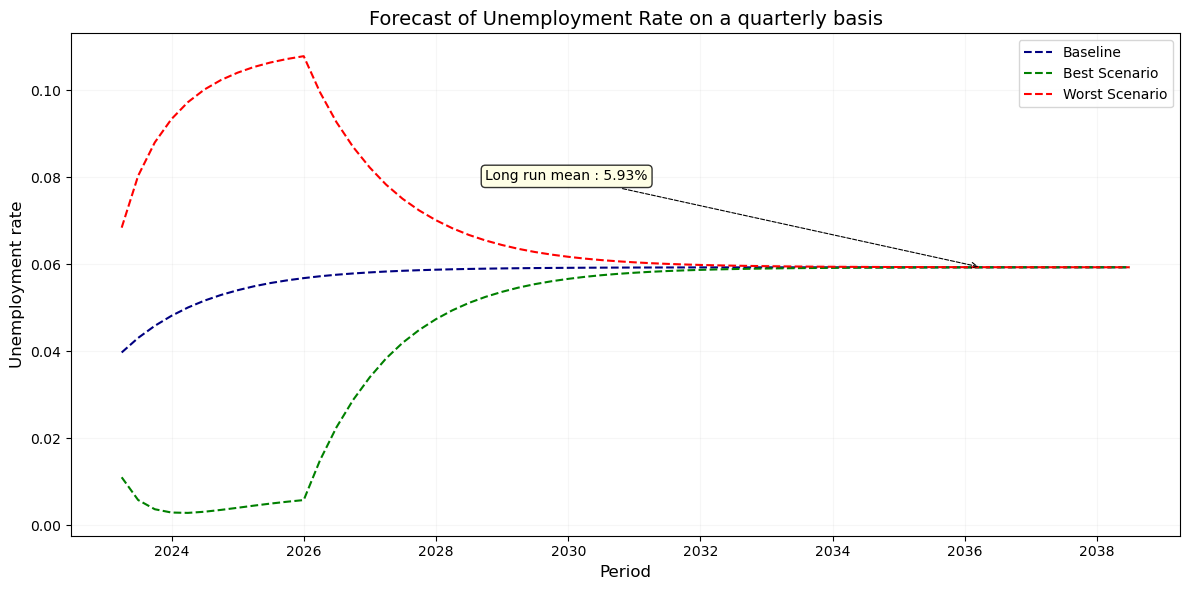

In [12]:
mev_forecast_extended = pd.DataFrame()
variance_forecast = np.empty(100)
variance_forecast[0] = std_error**2
period = list(range(1,51))

base_unrate = mev_forecast["UNRATE_Base"].iloc[-1]
op_unrate = mev_forecast["UNRATE_Optimistic"].iloc[-1]
pess_unrate = mev_forecast["UNRATE_Pessimistic"].iloc[-1]

mev_forecast_extended["UNRATE_Base"] = (intercept*((1- slope**period)/(1-slope))+(slope**period)*base_unrate)

mev_forecast_extended["UNRATE_Optimistic"] = (intercept*((1- slope**period)/(1-slope))+(slope**period)*op_unrate)
mev_forecast_extended["UNRATE_Pessimistic"] = (intercept*((1- slope**period)/(1-slope))+(slope**period)*pess_unrate)

mev_forecast_extended
mev_forecast_extended = pd.concat([new_data,mev_forecast_extended], ignore_index=True)

mev_forecast_extended["observation_date"] = pd.to_datetime(mev_forecast_extended["observation_date"])
mev_forecast_extended["observation_date"] = pd.date_range(start=start_reporting_date,periods=len(mev_forecast_extended["observation_date"]),freq="QE")

# Plotting the Macroeconomic Forecast : 
plt.figure(figsize=(12,6))
plt.plot(mev_forecast_extended["observation_date"],mev_forecast_extended["UNRATE_Base"],linestyle="--",color="navy", label = "Baseline")
plt.plot(mev_forecast_extended["observation_date"],mev_forecast_extended["UNRATE_Optimistic"],linestyle="--",color="green", label = "Best Scenario")
plt.plot(mev_forecast_extended["observation_date"],mev_forecast_extended["UNRATE_Pessimistic"], linestyle="--", color="red", label="Worst Scenario")
plt.legend()
plt.xlabel("Period", fontsize=12)
plt.ylabel("Unemployment rate", fontsize = 12)
plt.title("Forecast of Unemployment Rate on a quarterly basis", fontsize = 14)
plt.annotate(f"Long run mean : {intercept/(1-slope)*100:.2f}%",
             xy=(mev_forecast_extended["observation_date"].iloc[52],intercept/(1-slope)),
             xytext =(mev_forecast_extended["observation_date"].iloc[22],intercept/(1-slope)+0.02),
             fontsize = 10,
             arrowprops = dict(arrowstyle="->",color="black",lw=0.8, linestyle="--",connectionstyle = "arc3,rad=0"),
            bbox=dict(boxstyle="round,pad=0.3",
                    facecolor="lightyellow",
                    edgecolor="black",
                    alpha=0.8))
plt.tight_layout()

plt.grid(alpha=0.1)

## Probability of Default Estimation : 

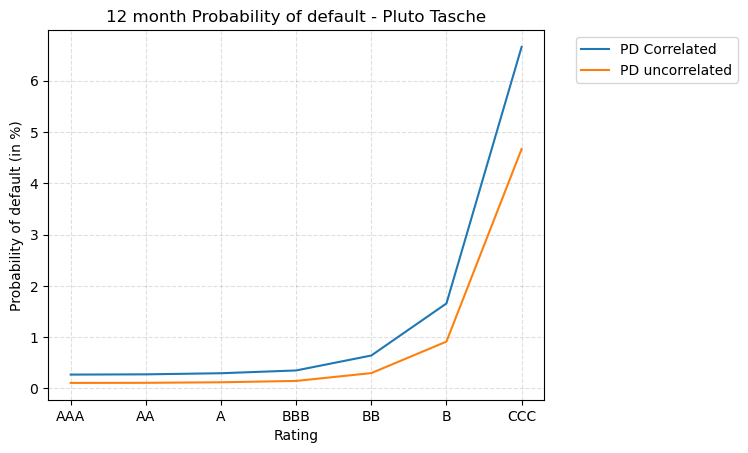

,Origination_Rating,Number of borrowers,Number of borrowers at or below current rating,Defaulters,PD estimation_Uncorrelated (%),PD_estimation_correlated (%),Lambda
0,AAA,26,1281,0,0.1082,0.2706,0.0027
1,AA,108,1255,0,0.1104,0.2753,0.0028
2,A,205,1147,0,0.1208,0.2971,0.0030
3,BBB,480,942,0,0.1471,0.3512,0.0035
4,BB,311,462,0,0.2996,0.6425,0.0064
5,B,122,151,0,0.9139,1.6577,0.0167
6,CCC,29,29,0,4.6679,6.6586,0.0689


 Note : Lambda is computed on the 'PD_estimation_correlated (%)' Column

In [13]:

rating_count = filtered_data.groupby("Origination_Rating")["Customer_ID"].count().reset_index()

# Adjusting the rating as AAA -> AA -> A -> BBB -> BB -> B -> CCC

rating_order = ["AAA","AA","A","BBB","BB","B","CCC"] # Change the Rating classification if there are different ratings assigned

rating_count['Origination_Rating'] = pd.Categorical(rating_count['Origination_Rating'], categories=rating_order, ordered=True)
rating_count = rating_count.sort_values("Origination_Rating").reset_index(drop=True)
rating_count = rating_count.rename(columns={"Customer_ID":"Number of borrowers"})

# Creating the Dataframe for PD computation (using Pluto Tasche method): 
total_borrowers = rating_count["Number of borrowers"].sum()
rating_count["Number of borrowers at or below current rating"] = rating_count["Number of borrowers"][::-1].cumsum()[::-1]

# The PD estimation is done under the assumption that there are 0 defaulters under each rating grade.
rating_count["Defaulters"]=0

rating_count["PD estimation_Uncorrelated (%)"] = (1-(1-0.75)**(1/rating_count["Number of borrowers at or below current rating"]))*100

asset_correlation = 0.12

trial_runs = 100000
target_cdf = 0.25

np.random.seed(42)
Z = np.random.normal(0,1,trial_runs)

def pluto_tasche_correlated(p_guess, k, n, Z, rho, target):
    p_guess = np.clip(p_guess, 1e-7,1-1e-7)
    
    p_star = stats.norm.cdf((stats.norm.ppf(p_guess)-np.sqrt(asset_correlation)*Z)/np.sqrt(1-asset_correlation))
    p_star = np.clip(p_star,1e-15,1-1e-15)
    
    #Computing the Cumulative binomial probabilites across all trial runs
    cumulative_prob = stats.binom.cdf(k=k,n=n, p=p_star)
    
    # Computing the expected value (mean) of the resulting probabilities (p*)
    average = np.mean(cumulative_prob)
    
    # Objective : The difference should be close to or exactly 0 ( ie., the mean should be 25%)
    return average - target

# Running the optimisation across all the grades

correlated_pd = []

for i in range(len(rating_count)):
    k = 0
    n = rating_count["Number of borrowers at or below current rating"].iloc[i]
    optimised_p = optimize.brentq(pluto_tasche_correlated,
                                  a = 1e-5, b= 1-1e-5,
                                  args = (k,n,Z,asset_correlation,target_cdf))
    
    correlated_pd.append(optimised_p*100)

rating_count["PD_estimation_correlated (%)"] = correlated_pd
                     
rating_count["Lambda"] = -np.log(1-(rating_count["PD_estimation_correlated (%)"]/100))
# The lambda will be used to compute the lifetime PD for Stage 2 and Stage 3 accounts.

plt.plot(rating_count["Origination_Rating"],rating_count["PD_estimation_correlated (%)"], label="PD Correlated")
plt.plot(rating_count["Origination_Rating"],rating_count["PD estimation_Uncorrelated (%)"], label = "PD uncorrelated")
plt.xlabel("Rating")
plt.ylabel("Probability of default (in %)")
plt.legend(bbox_to_anchor=(1.05,1))
plt.grid(alpha=0.25,color="grey",linestyle="--")
plt.title("12 month Probability of default - Pluto Tasche")
plt.show()

display(rating_count)

console.print(" Note : Lambda is computed on the 'PD_estimation_correlated (%)' Column",style="bold")

In [14]:
def hazard_rate(t = 1000):
    
    ratings = ["AAA","AA","A","BBB","BB","B","CCC","D"]
    lambda_map = rating_count.set_index("Origination_Rating")["Lambda"]
    rating_lambda_map = dict(zip(ratings,lambda_map))
    pd_curve = pd.DataFrame(np.arange(0,t,1),columns=["Year"])
    
    for r in ratings :
        pd_curve[r] = (1- np.exp(-(rating_lambda_map[r]*pd_curve["Year"])) if r!="D" else 1)
    #Plotting
    plt.figure(figsize=(12,6))
    for r in ratings:
        if r=="D":
            plt.plot(pd_curve["Year"], pd_curve[r], label = r, linewidth=2,color="Black")
        else:
            plt.plot(pd_curve["Year"], pd_curve[r], label = r)
    plt.ylabel("PD %")
    plt.xlabel("Time Period")
    plt.legend(bbox_to_anchor=(1.1,1))
    plt.title("Cumulative PD over the years using Hazard Rate Model")
    plt.grid(alpha=0.5,axis="y",color="grey",linestyle="--")
    #plt.savefig("Hazard_Rate",dpi=600)

widgets.interact(hazard_rate,t=widgets.IntSlider(value=61,min=1,max=100, step=4,description="Time Period", continuous_update=False))

interactive(children=(IntSlider(value=61, continuous_update=False, description='Time Period', min=1, step=4), …

<function __main__.hazard_rate(t=1000)>

### We have the Macroeconomic index for Base, Pessimistic and Optimistic Scenario in our 'mev_forecast' dataset, and our estimate of the PD value in 'rating_count' dataset we now need to map those Z values with our forecasting_data and assign the PD to each borrower. 

In [15]:
"""
Getting the PMT, RAW O/s balance for bullet and amrortising loans. 
For bullet loans, a simple interest is assumed and the borrower pays interest amount on a monthly basis. 
   
"""

is_amortising_loan = forecasting_data["Type_of_Loan"].isin(["Amortising"]) 

rate = forecasting_data["Origination_Interest_Rate"]/12  # Monthly interest rate
principal_amount =forecasting_data["Sanction_Amount (in USD)"]
periods = forecasting_data["Tenure"]

emi = (principal_amount * rate * ((1+rate)**periods))/((1+rate)**periods-1)

forecasting_data["PMT_new"] = np.where(is_amortising_loan== True,
                                            emi,0)

forecasting_data["MOB"] = ((forecasting_data["Reporting_Date"].dt.year - forecasting_data["Sanction_Date"].dt.year) * 12) + (forecasting_data["Reporting_Date"].dt.month - forecasting_data["Sanction_Date"].dt.month)

forecasting_data = forecasting_data.merge(rating_count[["Origination_Rating", "Lambda"]], 
                                                    left_on="Origination_Rating", 
                                                    right_on="Origination_Rating")



# Getting the Outstanding balance at each reporting quarter
pmt =forecasting_data["PMT_new"]
monthly_rate = forecasting_data["Origination_Interest_Rate"]/12
t = forecasting_data["Tenure"]
n = forecasting_data["MOB"]

#Default Setting The O/s balance value for all loan types as 0 : 
forecasting_data["Outstanding_Balance"] = 0.0 # It makes sure that revolving loans

# 1 : Amortising Loans Outstanding balance Computation : 

# FOR NOW DECREASING O/S BALANCE IS DONE, NEED TO ADJUST FOR DEFAULTS, i.e, ADDING INTEREST IN CASE OF DEFAULTS 

forecasting_data.loc[is_amortising_loan,"Outstanding_Balance"]=(pmt*((1-(1+monthly_rate)**-(t-n))/(monthly_rate)))
                                                        
# Outstanding balance would be treated as "EAD" for amortising, revolving and bullet loans

# 2 : Bullet Loans Outstanding Balance Cmputation : 

is_bullet_loan = forecasting_data["Type_of_Loan"].isin(["Bullet"])
forecasting_data.loc[is_bullet_loan,"Outstanding_Balance"] =forecasting_data["Sanction_Amount (in USD)"]

# 3. Revolving Loans : --> O/s Balance would be the Drawn balance, EAD amount would be computed in a seperate column. 
revolving_low = 0.5 # 50%
revolving_high = 0.95 # 95%

rand_ = forecasting_data.groupby("Customer_ID")["Customer_ID"].transform(lambda x : np.random.uniform(low=revolving_low, high=revolving_high, size = len(x)))

is_revolving_loan = forecasting_data["Type_of_Loan"].isin(["Revolving"])

forecasting_data.loc[is_revolving_loan,"Outstanding_Balance"] = rand_ * forecasting_data["Sanction_Amount (in USD)"]

#Getting the forecast of the Macroeconomic variable (Unemployment rate) {See documentation on why only one variable is chosen}

forecasting_data = forecasting_data.merge(mev_forecast[["observation_date","Z_Base","Z_Optimistic","Z_Pessimistic"]], 
                                         left_on="Reporting_Date",
                                         right_on="observation_date",
                                         how = "left")

# CCF for revolving loans : 
CCF = {"Commercial" : 45, # 45%
       "Retail" : 75,     # 75%
       "Corporate" : 50,  # 50%
       "SME" : 75}        # 75%

rho_CCF = 0.12 # 12%

forecasting_data["CCF %"] = forecasting_data["Segment"].map(CCF)

forecasting_data["CCF_Base"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["CCF %"]/100) - np.sqrt(rho_CCF)*forecasting_data["Z_Base"])/np.sqrt(1-rho_CCF))
forecasting_data["CCF_Optimistic"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["CCF %"]/100)-np.sqrt(rho_CCF)*forecasting_data["Z_Optimistic"])/np.sqrt(1-rho_CCF))
forecasting_data["CCF_Pessimistic"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["CCF %"]/100)-np.sqrt(rho_CCF)*forecasting_data["Z_Pessimistic"])/np.sqrt(1-rho_CCF))

# LGD is set as per the Segments, which is then adjusted to macroeconomic forecasts: 

LGD = {"Commercial": 65, #65%
      "Corporate" : 70,  #65%
      "Retail" : 60,     #60%
      "SME" : 60}        #60%

rho_LGD = 0.12 # 12%

forecasting_data["LGD %"] = forecasting_data["Segment"].map(LGD)

forecasting_data["LGD_Base"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["LGD %"]/100) - np.sqrt(rho_LGD)*forecasting_data["Z_Base"])/np.sqrt(1-rho_LGD))
forecasting_data["LGD_Optimistic"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["LGD %"]/100) - np.sqrt(rho_LGD)*forecasting_data["Z_Optimistic"])/np.sqrt(1-rho_LGD))
forecasting_data["LGD_Pessimistic"] = stats.norm.cdf((stats.norm.ppf(forecasting_data["LGD %"]/100) - np.sqrt(rho_LGD)*forecasting_data["Z_Pessimistic"])/np.sqrt(1-rho_LGD))

forecasting_data["Year_left"] = (forecasting_data["Tenure"] - forecasting_data["MOB"])/12
forecasting_data

,Customer_ID,Segment,Sector,Sanction_Amount (in USD),Outstanding_Balance,Type_of_Loan,Tenure,Maturity_Date,Loan_Duration_Flag,Sanction_Date,Origination_Rating,Origination_Interest_Rate,Secured_Unsecured_Flag,Collateral_Type,Collateral_Value,Reporting_Date,Reporting Date,MOB,end_date_amort,start_date_clipped,end_date,reporting_end_date,Quarter_Count,Total_Periods,Quarter_Index,Q_Count_for_Rating_Est.,PMT_new,Lambda,observation_date,Z_Base,Z_Optimistic,Z_Pessimistic,CCF %,CCF_Base,CCF_Optimistic,CCF_Pessimistic,LGD %,LGD_Base,LGD_Optimistic,LGD_Pessimistic,Year_left
0,CUST000001QA,Commercial,Logistics,2730256,1673601.4636,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-03-31,2025-12-31,102,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,0,34,29189.3272,0.0167,2023-03-31,0.9663,2.3014,-0.3687,45,0.3118,0.1626,0.5009,65,0.5215,0.3303,0.7078,6.5000
1,CUST000001QA,Commercial,Logistics,2730256,1627115.1640,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-06-30,2025-12-31,105,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,1,35,29189.3272,0.0167,2023-06-30,0.8106,2.5448,-0.9237,45,0.3324,0.1415,0.5820,65,0.5444,0.2984,0.7739,6.2500
2,CUST000001QA,Commercial,Logistics,2730256,1579467.6289,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-09-30,2025-12-31,108,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,2,36,29189.3272,0.0167,2023-09-30,0.6814,2.6434,-1.2806,45,0.3499,0.1335,0.6327,65,0.5632,0.2859,0.8116,6.0000
3,CUST000001QA,Commercial,Logistics,2730256,1530629.8507,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2023-12-31,2025-12-31,111,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,3,37,29189.3272,0.0167,2023-12-31,0.5743,2.6787,-1.5300,45,0.3647,0.1307,0.6668,65,0.5787,0.2815,0.8354,5.7500
4,CUST000001QA,Commercial,Logistics,2730256,1480572.0967,Amortising,180,2029-09-30,Long Term,2014-09-15,B,0.0991,Secured,Inventory,3665558.1300,2024-03-31,2025-12-31,114,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,4,38,29189.3272,0.0167,2024-03-31,0.4856,2.6824,-1.7113,45,0.3770,0.1304,0.6907,65,0.5915,0.2810,0.8515,5.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14728,CUST001499JO,SME,F&B,519844,519844.0000,Bullet,240,2031-02-28,Long Term,2011-02-01,BBB,0.0586,Secured,Real Estate,742888.3600,2025-09-30,2025-12-31,175,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,10,58,0.0000,0.0035,2025-09-30,0.1948,2.5631,-2.1734,75,0.7412,0.4100,0.9359,60,0.5785,0.2494,0.8583,5.4167
14729,CUST001499JO,SME,F&B,519844,519844.0000,Bullet,240,2031-02-28,Long Term,2011-02-01,BBB,0.0586,Secured,Real Estate,742888.3600,2025-12-31,2025-12-31,178,2025-12-31,2023-03-31,2025-12-31,2025-12-31,11,12,11,59,0.0000,0.0035,2025-12-31,0.1710,2.5453,-2.2034,75,0.7440,0.4126,0.9373,60,0.5820,0.2515,0.8608,5.1667
14730,CUST001500CM,Commercial,Logistics,49945738,49945738.0000,Bullet,60,2023-09-30,Long Term,2018-09-16,AA,0.0459,Secured,Equipment,61677261.1400,2023-03-31,2025-12-31,54,2023-09-30,2023-03-31,2023-09-30,2023-09-30,2,3,0,18,0.0000,0.0028,2023-03-31,0.9663,2.3014,-0.3687,45,0.3118,0.1626,0.5009,65,0.5215,0.3303,0.7078,0.5000
14731,CUST001500CM,Commercial,Logistics,49945738,49945738.0000,Bullet,60,2023-09-30,Long Term,2018-09-16,AA,0.0459,Secured,Equipment,61677261.1400,2023-06-30,2025-12-31,57,2023-09-30,2023-03-31,2023-09-30,2023-09-30,2,3,1,19,0.0000,0.0028,2023-06-30,0.8106,2.5448,-0.9237,45,0.3324,0.1415,0.5820,65,0.5444,0.2984,0.7739,0.2500


In [16]:
summary = pd.DataFrame(forecasting_data[(forecasting_data["Type_of_Loan"]=="Revolving") & (forecasting_data["Reporting_Date"]=="2023-03-31")].groupby(["Segment", "Sector", "Type_of_Loan"])["Customer_ID"].count())
summary.rename(columns={"Customer_ID" : "Count"},inplace=True)
summary

Count
Segment    Sector              Type_of_Loan       
Commercial Logistics           Revolving        16
           Real Estate         Revolving        12
           Retail Trade        Revolving        15
           Wholesale           Revolving        22
Corporate  Energy              Revolving         9
           Finance             Revolving        12
           Healthcare          Revolving         8
           Manufacturing       Revolving        15
           Tech                Revolving        14
Retail     Credit Card         Revolving       179
           Personal Loan       Revolving        67
SME        Construction        Revolving        19
           F&B                 Revolving        14
           Light Manufacturing Revolving        13
           Local Services      Revolving        13

# TTC and PIT Transition Matrix :

In [17]:
ratings = ["AAA","AA","A","BBB","BB","B","CCC","D"]
raw_transition_matrix = pd.DataFrame(index=ratings)

#raw_transition_matrix["Rating"] = ["AAA" , "AA"  , "A"  , "BBB" , "BB"  , "B"   , "CCC" ,  "D"]
raw_transition_matrix["AAA"]    = [86.99 , 0.50  ,0.03  , 0.01  , 0.01  , 0.00  , 0.00   ,  0.00 ]
raw_transition_matrix["AA"]     = [9.12  , 87.06 ,1.69  , 0.09  , 0.03  , 0.02  , 0.00   ,  0.00 ]
raw_transition_matrix["A"]      = [0.53  , 7.85  ,88.17 , 3.42  , 0.11  , 0.08  , 0.11   ,  0.00 ]
raw_transition_matrix["BBB"]    = [0.05  , 0.49  ,5.16  , 86.04 , 4.83  , 0.17  , 0.20   ,  0.00 ]
raw_transition_matrix["BB"]     = [0.08  , 0.05  ,0.29  , 3.62  , 77.50 , 4.93  , 0.59   ,  5.0  ]
raw_transition_matrix["B"]      = [0.03  , 0.06  ,0.12  , 0.46  , 6.65  , 74.53 , 13.21  ,  7.0  ]
raw_transition_matrix["CCC"]    = [0.05  , 0.02  ,0.02  , 0.11  , 0.55  , 4.42  , 43.51  ,  35.0 ]
raw_transition_matrix["D"]      = [0.00  , 0.02  ,0.06  , 0.17  , 0.65  , 3.44  ,26.89   ,  45.0 ]
raw_transition_matrix["NR"]     = [3.15  , 3.94  ,4.48  , 6.10  , 9.67  , 12.41 , 15.50  ,  8.0  ]

console.print(" -------------- Raw yearly Transition Matrix ---------------",style="bold")
display(raw_transition_matrix)

raw_transition_matrix= raw_transition_matrix / 100
raw_transition_matrix["1_NR"] = 1- raw_transition_matrix["NR"]
#Adjusting the transition matrix probabilities by removing the "NR" category
annual_transition_matrix= raw_transition_matrix.iloc[:,:-2].divide(raw_transition_matrix["1_NR"],axis=0)

#temp = transition_matrix.cumsum(axis=1)

# Adjusting the prbabilites for each row such that the sum of row is 100%
row_sums = annual_transition_matrix.sum(axis=1)
annual_transition_matrix = annual_transition_matrix.divide(row_sums,axis=0)

console.print(" --------------  Adjusted Cumulative Yearly TTC Transiton Matrix ---------------",style="bold")
cumulative_transition_matrix = annual_transition_matrix.cumsum(axis=1)
display(cumulative_transition_matrix)

# The TTC yearly matrix needs to be converted to a quarterly TTC matrix : 

quarterly_matrix = fractional_matrix_power(annual_transition_matrix, 0.25)

clean_quarterly_matrix = np.real(quarterly_matrix)
clean_quarterly_matrix = clean_quarterly_matrix.clip(min=0)
clean_quarterly_matrix.cumsum(axis=1)

row_sums = clean_quarterly_matrix.sum(axis=1, keepdims=True)
normalized_quarterly_matrix = clean_quarterly_matrix / row_sums

transition_matrix = pd.DataFrame(normalized_quarterly_matrix, index=ratings, columns=ratings)

cumulative_transition_matrix = transition_matrix.cumsum(axis=1)

console.print("--------------- Final Quarterly Cumulative TTC Transition Matrix -------------- ",style="bold")

display(cumulative_transition_matrix)

 -------------- Raw yearly Transition Matrix ---------------

,AAA,AA,A,BBB,BB,B,CCC,D,NR
AAA,86.9900,9.1200,0.5300,0.0500,0.0800,0.0300,0.0500,0.0000,3.1500
AA,0.5000,87.0600,7.8500,0.4900,0.0500,0.0600,0.0200,0.0200,3.9400
A,0.0300,1.6900,88.1700,5.1600,0.2900,0.1200,0.0200,0.0600,4.4800
BBB,0.0100,0.0900,3.4200,86.0400,3.6200,0.4600,0.1100,0.1700,6.1000
BB,0.0100,0.0300,0.1100,4.8300,77.5000,6.6500,0.5500,0.6500,9.6700
B,0.0000,0.0200,0.0800,0.1700,4.9300,74.5300,4.4200,3.4400,12.4100
CCC,0.0000,0.0000,0.1100,0.2000,0.5900,13.2100,43.5100,26.8900,15.5000
D,0.0000,0.0000,0.0000,0.0000,5.0000,7.0000,35.0000,45.0000,8.0000


 --------------  Adjusted Cumulative Yearly TTC Transiton Matrix ---------------

,AAA,AA,A,BBB,BB,B,CCC,D
AAA,0.8982,0.9924,0.9978,0.9983,0.9992,0.9995,1.0000,1.0000
AA,0.0052,0.9116,0.9933,0.9984,0.9990,0.9996,0.9998,1.0000
A,0.0003,0.0180,0.9409,0.9949,0.9979,0.9992,0.9994,1.0000
BBB,0.0001,0.0011,0.0375,0.9536,0.9921,0.9970,0.9982,1.0000
BB,0.0001,0.0004,0.0017,0.0551,0.9131,0.9867,0.9928,1.0000
B,0.0000,0.0002,0.0011,0.0031,0.0594,0.9103,0.9607,1.0000
CCC,0.0000,0.0000,0.0013,0.0037,0.0106,0.1670,0.6818,1.0000
D,0.0000,0.0000,0.0000,0.0000,0.0543,0.1304,0.5109,1.0000


--------------- Final Quarterly Cumulative TTC Transition Matrix -------------- 

,AAA,AA,A,BBB,BB,B,CCC,D
AAA,0.9734,0.9988,0.9995,0.9995,0.9998,0.9998,1.0000,1.0000
AA,0.0014,0.9769,0.9988,0.9996,0.9997,0.9999,1.0000,1.0000
A,0.0001,0.0048,0.9846,0.9989,0.9995,0.9998,0.9998,1.0000
BBB,0.0000,0.0002,0.0099,0.9878,0.9983,0.9993,0.9995,1.0000
BB,0.0000,0.0001,0.0002,0.0149,0.9765,0.9971,0.9981,1.0000
B,0.0000,0.0001,0.0003,0.0005,0.0161,0.9746,0.9895,1.0000
CCC,0.0000,0.0000,0.0004,0.0014,0.0014,0.0538,0.8489,1.0000
D,0.0000,0.0000,0.0000,0.0000,0.0200,0.0316,0.2138,1.0000


##### Computing the PIT_Tansition Matrix for each reported quarter : 

In [18]:

"""
    There are 12 reported quarters spanning from March 31st 2023 to December 31st 2025.
    Furthermore, there are 3 cases being considered : Base, Optimistic, Pessimistic, thus
    there will be a total of 36 pit_transition_matrix. 
    For computational purposes, a flat 12% correlation is considered.
"""

# ---------- DPD transition Matrix : 

dpd_tm = np.array([
    [0.90,0.05,0.04,0.01],
    [0.20,0.65,0.05,0.10],
    [0.10,0.05,0.80,0.05],
    [0.01,0.01,0.03,0.95]
])
vals = ["Current", "30-59 DPD", "60-89 DPD","90+ DPD"]
dpd_transition_matrix = pd.DataFrame(dpd_tm, index = vals, columns = vals)

cumulative_dpd_transition_matrix = dpd_transition_matrix.cumsum(axis=1)
cumulative_dpd_transition_matrix

# Point in Time DPD Transition Matrix : 

# -- Lower Bound Dpd

lower_bound_dpd = pd.DataFrame(index = dpd_transition_matrix.index, columns=dpd_transition_matrix.columns)

lower_bound_dpd = dpd_transition_matrix.iloc[:,::-1].cumsum(axis=1).iloc[:,::-1]
lower_bound_dpd.iloc[:,:-1] = stats.norm.ppf(lower_bound_dpd.iloc[:,1:])
lower_bound_dpd.iloc[:,-1] = -10000

upper_bound_dpd = lower_bound_dpd.shift(axis=1).fillna(10000)


rho = 0.12  # Correlation to be used in the vasicek model for conversion of TTC- TM to PIT-TM
 
# --------------------- Quarter end dates : ----------

# start_of_reporting_date = 31st march 2023, and end_reporting_date = 31st December 2025 :

quarter_dates = pd.date_range(start= start_of_reporting_date, end=end_reporting_date,freq="QE")

# -----------------Lower Bound Rating : ---------------------

lower_bound_tm = pd.DataFrame(index = cumulative_transition_matrix.index, columns=cumulative_transition_matrix.columns)

lower_bound_tm = transition_matrix.iloc[:,::-1].cumsum(axis=1).iloc[:,::-1]

# Taking the inverse of the standard normal distribution of the lower_bound_tm :
lower_bound_tm.iloc[:,:-1] = stats.norm.ppf(lower_bound_tm.iloc[:,1:])
lower_bound_tm.iloc[:,-1] = -10000

# ----Upper Bound :
upper_bound_tm = lower_bound_tm.shift(axis=1).fillna(10000).copy()

# ---Empty Point in time transition matrix -------
pit_transition_matrix = pd.DataFrame(index = cumulative_transition_matrix.index, columns = cumulative_transition_matrix.columns)

# ======================= Computation of PIT-Transition Matrices (Rating and DPD) :

scenarios = ["Z_Optimistic","Z_Base","Z_Pessimistic"]

scenario_count = 0
total_count = 0

pit_tm_dict = {}
pit_dpd_tm_dict = {}

PIT_tm_dict_non_cum = {} # Used for non cumulative transition matrix
for s in range(len(scenarios)):
    
    for q in range(len(quarter_dates)):
        
        Z_val = mev_forecast.loc[mev_forecast["observation_date"]==quarter_dates[q],scenarios[s]].values[0]
        
        pit_vals = stats.norm.cdf((upper_bound_tm - np.sqrt(rho) * Z_val)/np.sqrt(1-rho)) - \
                   stats.norm.cdf((lower_bound_tm - np.sqrt(rho) * Z_val)/np.sqrt(1-rho))
        
        # Coversion to the dataframe : 
        pit_transition_matrix = pd.DataFrame(pit_vals.cumsum(axis=1), index= cumulative_transition_matrix.index, columns= cumulative_transition_matrix.columns)
        dictionary_key_title = f"{quarter_dates[q].date()}_{scenarios[s].removeprefix('Z_')}"
        
        # Inserting the transition matrix onto a Dictionary : 
        pit_tm_dict.update({dictionary_key_title : pit_transition_matrix}) 

        # -----------------------------------------------
        # Non Cumulative Transition matrix : 
        transition_matrix_non_cumulative = pd.DataFrame(pit_vals, index= cumulative_transition_matrix.index, columns= cumulative_transition_matrix.columns)
        PIT_tm_dict_non_cum.update({dictionary_key_title : transition_matrix_non_cumulative})
        # -----------------------------------------------
        
        print(f"\033[1mCumulative PIT Transition Matrix for date: {quarter_dates[q].date()}; Scenario: {scenarios[s].removeprefix('Z_')} and a Z of {Z_val:.5f}\033[0m")
        display(pit_transition_matrix)
        
        # ----------- PIT - DPD Transition Matrix : 
        
        dpd_vals = stats.norm.cdf((upper_bound_dpd - np.sqrt(rho)*Z_val)/np.sqrt(1-rho)) - \
        stats.norm.cdf((lower_bound_dpd - np.sqrt(rho)*Z_val)/np.sqrt(1-rho))
        
        # Conversion to DataFrame : 
        
        pit_dpd_tm = pd.DataFrame(dpd_vals.cumsum(axis=1), index=cumulative_dpd_transition_matrix.index, columns= cumulative_dpd_transition_matrix.columns)
        dictionary_key_title = f"{quarter_dates[q].date()}_{scenarios[s].removeprefix('Z_')}"
        
        # Inserting the DataFrame into a Dictionary : 
        
        pit_dpd_tm_dict.update({dictionary_key_title :pit_dpd_tm})
        
        print(f"\033[1mCumulative DPD Transition Matrix for Date : {quarter_dates[q].date()} ; Scenario : {scenarios[s].removeprefix('Z_')} and a Z of {Z_val:.5f}\033[0m")
        display(pit_dpd_tm)
        
        total_count+=1
        
print(f"total Runs : {total_count}")

Cumulative PIT Transition Matrix for date: 2023-03-31; Scenario: Optimistic and a Z of 2.30138


,AAA,AA,A,BBB,BB,B,CCC,D
AAA,0.9982,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
AA,0.0098,0.9985,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
A,0.0007,0.0280,0.9992,1.0000,1.0000,1.0000,1.0000,1.0000
BBB,0.0003,0.0018,0.0511,0.9994,1.0000,1.0000,1.0000,1.0000
BB,0.0003,0.0010,0.0018,0.0711,0.9985,0.9999,1.0000,1.0000
B,0.0000,0.0006,0.0024,0.0036,0.0758,0.9983,0.9995,1.0000
CCC,0.0000,0.0000,0.0035,0.0098,0.0098,0.1934,0.9744,1.0000
D,0.0000,0.0000,0.0000,0.0000,0.0902,0.1292,0.5017,1.0000


Cumulative DPD Transition Matrix for Date : 2023-03-31 ; Scenario : Optimistic and a Z of 2.30138


,Current,30-59 DPD,60-89 DPD,90+ DPD
Current,0.9867,0.9954,0.9996,1.0000
30-59 DPD,0.4811,0.9747,0.9867,1.0000
60-89 DPD,0.3028,0.3994,0.9954,1.0000
90+ DPD,0.0515,0.0902,0.1831,1.0000


Cumulative PIT Transition Matrix for date: 2023-06-30; Scenario: Optimistic and a Z of 2.54476


...

Cumulative PIT Transition Matrix for date: 2025-12-31; Scenario: Pessimistic and a Z of -2.20335


,AAA,AA,A,BBB,BB,B,CCC,D
AAA,0.8939,0.9925,0.9962,0.9967,0.9981,0.9986,1.0000,1.0000
AA,0.0000,0.9052,0.9921,0.9974,0.9981,0.9992,0.9996,1.0000
A,0.0000,0.0002,0.9315,0.9930,0.9965,0.9985,0.9985,1.0000
BBB,0.0000,0.0000,0.0005,0.9435,0.9895,0.9951,0.9964,1.0000
BB,0.0000,0.0000,0.0000,0.0009,0.9038,0.9833,0.9886,1.0000
B,0.0000,0.0000,0.0000,0.0000,0.0010,0.8977,0.9500,1.0000
CCC,0.0000,0.0000,0.0000,0.0000,0.0000,0.0057,0.6125,1.0000
D,0.0000,0.0000,0.0000,0.0000,0.0013,0.0026,0.0485,1.0000


Cumulative DPD Transition Matrix for Date : 2025-12-31 ; Scenario : Pessimistic and a Z of -2.20335


,Current,30-59 DPD,60-89 DPD,90+ DPD
Current,0.7097,0.8263,0.9522,1.0000
30-59 DPD,0.0436,0.6146,0.7097,1.0000
60-89 DPD,0.0146,0.0275,0.8263,1.0000
90+ DPD,0.0005,0.0013,0.0051,1.0000


total Runs : 36


####  Computation of Point in time CCF :

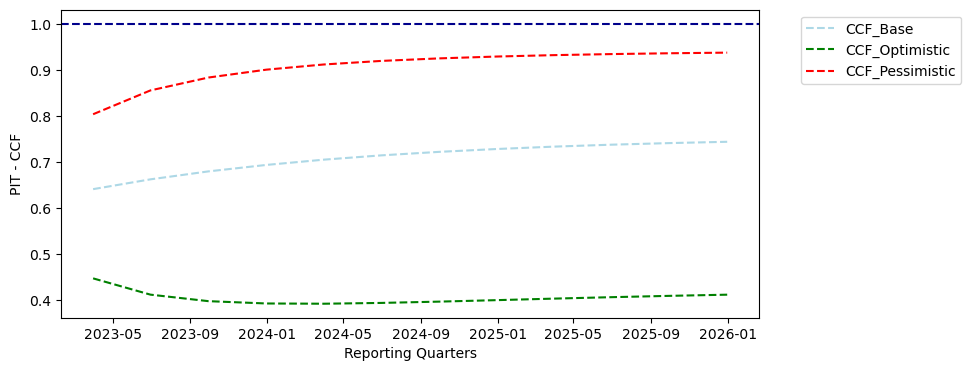

,observation_date,UNRATE,UNRATE_lag,UNRATE_Base,UNRATE_Optimistic,UNRATE_Pessimistic,Z_Base,Z_Optimistic,Z_Pessimistic,CCF_Base,CCF_Optimistic,CCF_Pessimistic
70,2022-12-31,0.0357,0.0353,0.0357,NaN,NaN,1.1542,NaN,NaN,0.6152,NaN,NaN
71,2023-03-31,NaN,NaN,0.0397,0.0110,0.0684,0.9663,2.3014,-0.3687,0.6414,0.4480,0.8038
72,2023-06-30,NaN,NaN,0.0431,0.0058,0.0804,0.8106,2.5448,-0.9237,0.6626,0.4127,0.8554
73,2023-09-30,NaN,NaN,0.0458,0.0036,0.0880,0.6814,2.6434,-1.2806,0.6799,0.3985,0.8834
74,2023-12-31,NaN,NaN,0.0481,0.0029,0.0934,0.5743,2.6787,-1.5300,0.6939,0.3935,0.9004
75,2024-03-31,NaN,NaN,0.0500,0.0028,0.0973,0.4856,2.6824,-1.7113,0.7053,0.3930,0.9116
76,2024-06-30,NaN,NaN,0.0516,0.0031,0.1002,0.4120,2.6702,-1.8463,0.7146,0.3947,0.9194
77,2024-09-30,NaN,NaN,0.0529,0.0035,0.1024,0.3510,2.6504,-1.9485,0.7222,0.3975,0.9249
78,2024-12-31,NaN,NaN,0.0540,0.0040,0.1041,0.3004,2.6278,-2.0270,0.7284,0.4008,0.9289
79,2025-03-31,NaN,NaN,0.0549,0.0045,0.1054,0.2584,2.6048,-2.0879,0.7335,0.4040,0.9319


In [19]:
"""
The following is an iillustration of CCF values over the reported period for Retail and SME Revolving loans, where a 
flat CCF of 75% is selected and adjusted as per macroeconomic condition.

"""

CCF = 0.75
correlation = 0.12

mev_forecast["Z_Base"] = -(mev_forecast["UNRATE_Base"] - mu)/sigma
mev_forecast["Z_Optimistic"] = -(mev_forecast["UNRATE_Optimistic"] - mu)/sigma
mev_forecast["Z_Pessimistic"] = -(mev_forecast["UNRATE_Pessimistic"] - mu)/sigma

mev_forecast["CCF_Base"] = stats.norm.cdf((stats.norm.ppf(CCF)-np.sqrt(correlation)*mev_forecast["Z_Base"])/np.sqrt(1-correlation))
mev_forecast["CCF_Optimistic"] = stats.norm.cdf((stats.norm.ppf(CCF)-np.sqrt(correlation)*mev_forecast["Z_Optimistic"])/np.sqrt(1-correlation))
mev_forecast["CCF_Pessimistic"] = stats.norm.cdf((stats.norm.ppf(CCF)-np.sqrt(correlation)*mev_forecast["Z_Pessimistic"])/np.sqrt(1-correlation))

plt.figure(figsize=(9,4))
plt.plot(mev_forecast["observation_date"].iloc[71:],mev_forecast["CCF_Base"].iloc[71:],label= "CCF_Base",linestyle="--", color="lightblue")
plt.plot(mev_forecast["observation_date"].iloc[71:],mev_forecast["CCF_Optimistic"].iloc[71:], label = "CCF_Optimistic", linestyle="--",color = "green")
plt.plot(mev_forecast["observation_date"].iloc[71:],mev_forecast["CCF_Pessimistic"].iloc[71:], label = "CCF_Pessimistic",linestyle="--",color = "red")
plt.ylabel("PIT - CCF")
plt.xlabel("Reporting Quarters")
plt.axhline(y=1, linestyle="--", color="darkblue")
#plt.axhline(y = CCF, linestyle ="-", color = "orange", label = "Assumed value of CCF")
plt.legend(bbox_to_anchor=(1.05,1))

plt.show()
display(mev_forecast.tail(13))


# Markov Chain Simulation

In [20]:

ratings = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "D"]
buckets = ["Current","30-59 DPD","60-89 DPD","90+ DPD"]

sanction_probation_count = 0

trial_list = []

def fq_rating_estimation(runs,x, rating_estimation=True, initial_probation = 0, probabilities = None,  return_history = False):
    
    # This is used to get the first reported quarter rating estimate.
    
    """
    The function runs a markov chain simulation for 1st reported quarter given the Sanction rating.
    The parameters of the function are : 
    - runs = Takes in the number between the sanction date and the first reporting date, accepts positive integers only
    - x = a scalar str value, which can be either the Sanction rating of the counterparty or the bucket at the time of Sanction, ie., "Current"
    - rating_estimation = True ; The function by defaults computes the rating transitions, setting to False would compute the DPD transition.
    - initial_probation = default 0 ; The parameter extracts the number of periods remaining on the probation if the account was marked as "D"
                          during the probation_period check. 
                          
                          For example, if account was marked as "D"/ 90+ DPD in the 2nd last quarter, and the probation period is 4 period, the parameter
                          would take 2 signifying that the remaining period. If the account was defaulted in the last quarter, a direct probation period of 4
                          would apply.
    - probabilities : A list of transition probabilities for the markov simulation. The length must be equal to the number of runs
    - return_history : default : False, Returns a list,
                       To get the list of all past estimates upto the current estimate of DPD/ Rating, set the variable to True.
    """
    chosen_vals = []
    probability = []
    probability = probabilities
    
    historical_estimates = []
    
    borrower_val = x # DPD or Rating
    
    if rating_estimation ==True:
        matrix = cumulative_transition_matrix # Use of the TTC - Transition matrix to get the Credit Rating
        vector = ratings
    else:
        matrix = cumulative_dpd_transition_matrix # Use of DPD TTC - transition Matrix 
        vector = buckets
        
    for i  in range(runs): # The number of loops (or quarterrs) the simulation needs to run.

        cumulative_probs = matrix.loc[borrower_val].values
        
        random_draws = np.atleast_1d(probabilities[i]) #np.random.rand(1)
        
        indices = np.searchsorted(cumulative_probs, random_draws)
        
        chosen_vals = [vector[j]  for j in indices] # Mapping indices back to original ratings or DPD bucket
        
        historical_estimates.append(chosen_vals)
        
        borrower_val = chosen_vals[-1] # Updating the borrower rating for the next iteration
        
        # Updating the rating for next iteration: 
        return_val = borrower_val
        
    if return_history ==True : 
        return return_val, historical_estimates 
    else:
        return return_val # Returns a Single rating or DPD bucket.

def rating_estimation(qcount, x ,reporting_date,scenario="Base", rating_estimation = True, required_probation_period = None, dpd = None, initial_probation_count = 0,
                      probabilities = None, return_history = False): 
    
    """
    The function runs a markov chain simulation for rating grades given the first reporting period rating.
    The parameters are : 
    
    - qcount = Takes in the number of quarters the estimation needs to be done, accept positive integers only
    
    - x = The previous period rating of the counterparty / DPD bucket of the counterparty
    
    - reporting_date = Should be in datetime format and it should exist in the data the analysis is being done.
    
    - scenario = There are 3 values accepted: 
                "Base", "Optimistic", "Pessimistic"
                This is used to fetch the required transition matrix.
                By default, the scenario is set as "Base".
    - rating_estimation = True, The function by defaults computes the credit rating transitions, setting to False would compute the DPD bucket transition.
    
    - required_probation_period : optional* scalar value
        This signifies the number of periods a borrower stays in the default caategory after clearning previous dues.
    
    - dpd : A list of DPD values estimated for the markov simulation. The length must be equal to the number of qcount
    
    - initial_probation_count : The probation count from the first reported quarter, default value of 0.
    
    - probabilities : A list of transition probabilities for the markov simulation. The length must be equal to the number of qcount
    
    - return_history : default : False, Returns a list,
                       To get the list of all past estimates upto the current estimate of DPD/ Rating, set the variable to True.
    
    """
    
    ret_vals = []
    chosen_vals = []
    act_dict = {}
    
    probation_flag = False
    
    historical_estimates = []
    
    dates = pd.date_range(start = reporting_date,
                          periods = qcount, freq="QE")
    
    borrower_val  = x
    
    if rating_estimation == True : 
        act_dict = pit_tm_dict
        vector = ratings
    else:
        act_dict = pit_dpd_tm_dict
        vector = buckets
    
    if required_probation_period is None : # Getting the DPD bucket estimations : 
    
        for i in range(qcount):
            
            random_draws = np.atleast_1d(probabilities[i])

            date = dates[i]
            date = date.strftime("%Y-%m-%d")
            dict_key = date + "_" + scenario
            
            matrix = act_dict[dict_key] # Getting the PIT- Transition matrix
            cumulative_probs = matrix.loc[borrower_val].values # Extracting the respective probabilites given the rating/ DPD Bucket
            
            indices = np.searchsorted(cumulative_probs, random_draws)
            
            chosen_vals = [vector[j] for j in indices] # Mapping indices back to original ratings
            
            # Updating the rating for next iteration: 
            borrower_val = chosen_vals[-1]
            ret_vals.extend(chosen_vals)
            
        return ret_vals
    
    
    elif required_probation_period is not None:
    # Getting the Credit rating estimation, would need the DPD bucket estimation here for the override based on the probation period.
        
        if borrower_val == "D":
            if dpd[0] == "90+ DPD":
                probation_count = required_probation_period
                probation_flag = True
            else:
                probation_count = initial_probation_count
                probation_flag = True
                    
        elif borrower_val != "D":
            if dpd[0] == "90+ DPD":
                probation_count = required_probation_period
                probation_flag = True
            else:
                probation_count = initial_probation_count
        
        for i in range(qcount):
            
            if dpd[i] == "90+ DPD": # Check 1 : If current DPD is 90+, the rating is forced to be "D". 
                ret_vals.extend("D")
                borrower_val = "D"
                probation_count= required_probation_period
                
            elif probation_count > 0 :
                chosen_vals = "D"
                ret_vals.extend(chosen_vals)
                borrower_val = chosen_vals
                
                probation_count -= 1
        
            else:
                    
                random_draws = np.atleast_1d(probabilities[i])

                date = dates[i]
                date = date.strftime("%Y-%m-%d")
                dict_key = date + "_" + scenario
                
                matrix = act_dict[dict_key] # Getting the PIT- Transition matrix
                
                cumulative_probs = matrix.loc[borrower_val].values # Extracting the respective probabilites given the rating/ DPD Bucket
                
                indices = np.searchsorted(cumulative_probs, random_draws)
                
                chosen_vals = [vector[j] for j in indices] # Mapping indices back to original ratings
                
                historical_estimates.append(chosen_vals)
                
                probation_time = required_probation_period
                
                temp_ratings = []
                
                if chosen_vals[-1]=="D":
                    if dpd[i] !="90+ DPD": # If rating estimate comes out to be "D" but the current DPD is not 90+, rating is re-estimated.
                        
                        iterations = 0
                        np.random.seed()
                        while True:
                            
                            random_draws = np.atleast_1d(np.random.rand())

                            indices = np.searchsorted(cumulative_probs, random_draws)

                            chosen_vals = [vector[j] for j in indices]
                            temp_ratings.append(chosen_vals)
                            
                            if chosen_vals[-1] != "D":
                                break
                        
                        borrower_val = chosen_vals[-1] # temp_vals[-1]
                        ret_vals.append(borrower_val)
                else:
                    borrower_val = chosen_vals[-1]
                    ret_vals.append(borrower_val)
        
        global trial_list
        trial_list = []
        
        trial_list = ret_vals
        
        
        if return_history == True:
            return ret_vals, historical_estimates
        else:
            return ret_vals
            

In [21]:
%%time

# trial_markov = forecasting_data.copy()

scen = ["Base", "Optimistic", "Pessimistic"]

estimated_rating_base = []
estimated_rating_pessimistic = []
estimated_rating_optimistic = []

dpd_bucket_base = []
dpd_bucket_optimistic = []
dpd_bucket_pessimistic = []

current_rating = []
previous_dpd = []
est_rating = []
chosen_vals = []
dpd_bucket = []
dpd_vals  = []

historical_dpd = []
historical_ratings = []

# DPD Check for EAD  Computation : 

DPD_EAD_Counter_Base = []
DPD_EAD_Counter_optimistic = []
DPD_EAD_Counter_pessimistic = []

required_probation_period = 2 
# The probation period as set by the risk committee. Change this variable as needed. Each increment in number would indicate 1 quarter. 
# For example, required_probation_period = 2 means a probation period of 2 quarters is applicable

probation_time_base = 0
probation_time_optimistic = 0
probation_time_pessimistic = 0

temp =[]
_4490dpd = []

EIR_annual = []
outflow = []
inflow = []
EIR_Final =[]
comp_vals = []
temp = []

reporting_90dpd_count_base = []
reporting_90dpd_count_optimistic = []
reporting_90dpd_count_pessimistic = []
counts = []

dpd_check = "90+ DPD"

rating = None

local_seed_dpd = np.random.default_rng(seed=42)
probabilities_dpd = local_seed_dpd.random(forecasting_data[forecasting_data["Quarter_Index"]==0]["Quarter_Count"].sum()) #local_seed_dpd.random(len(trial_markov))

local_seed_rating = np.random.default_rng(seed=52) 
probabilities_rating = local_seed_rating.random(forecasting_data[forecasting_data["Quarter_Index"]==0]["Quarter_Count"].sum()) #local_seed_rating.random(len(trial_markov)) 

local_seed_sanction_rating = np.random.default_rng(seed=72)
probabilities_sanction_rating = local_seed_sanction_rating.random(forecasting_data["Q_Count_for_Rating_Est."].sum())

local_seed_sanction_dpd = np.random.default_rng(seed=95)
probabilities_sanction_dpd = local_seed_sanction_dpd.random(forecasting_data["Q_Count_for_Rating_Est."].sum())

n = 0
quarter_count_est = 0

forecast_quarter_count_est = 0 


for n in range(len(forecasting_data)):

    
    if forecasting_data.loc[n,"Quarter_Index"] ==0 :
          
        if forecasting_data.loc[n,"Q_Count_for_Rating_Est."] == 0 :
            current_rating = forecasting_data.loc[n,"Origination_Rating"]
            
            estimated_rating_base.append(current_rating)
            estimated_rating_pessimistic.append(current_rating)
            estimated_rating_optimistic.append(current_rating)
            
            dpd_bucket_base.append("Current")        # DPD Starts at the Current State for newly originated Loans
            dpd_bucket_optimistic.append("Current")  # DPD Starts at the Current State for newly originated Loans
            dpd_bucket_pessimistic.append("Current") # DPD Starts at the Current State for newly originated Loans
            
            # probation_time for base, optimistic and pessimistic scenario would be 0 here.
            probation_time_base = 0
            probation_time_optimistic = 0
            probation_time_pessimistic = 0

            # dpd_counter for EAD : 
            DPD_EAD_Counter_Base.append(0)
            DPD_EAD_Counter_optimistic.append(0)
            DPD_EAD_Counter_pessimistic.append(0)
            
        else:
            rep_date = forecasting_data.loc[n,"Reporting_Date"]
            Quarter_runs = forecasting_data.loc[n,"Q_Count_for_Rating_Est."]
            orig_rating = forecasting_data.loc[n,"Origination_Rating"]
            
# —————————— 1 : Base Case scenario run
            
            # ---------- DPD Bucket Estimation : 
            probabilites = probabilities_sanction_dpd[quarter_count_est:quarter_count_est+Quarter_runs+1]
            
            dpd_bucket, historical_dpd = fq_rating_estimation(runs=Quarter_runs, x = "Current", rating_estimation = False, 
                                              probabilities = probabilites, return_history = True)
            
            dpd_bucket_base.append(dpd_bucket)
            
            # ---------- DPD Counter for EAD computation : 
            temp = [item for sublist in historical_dpd for item in sublist] # Creating a flat list out of the sublist
            
            count = sum(1 for _ in takewhile(lambda x: x == "90+ DPD", reversed(temp)))
            chosen_val = count
            DPD_EAD_Counter_Base.append(chosen_val)
            
            # ---------- Rating Estimation :
            
            probation_time_base = required_probation_period
            
            probation_time_base = 0
            last_90_position = None  # how many periods ago was the last 90+

            for index, d in enumerate(historical_dpd[-required_probation_period:][::-1]):
                if d[0] == dpd_check:
                    last_90_position = index  # 0 = last quarter, 1 = 2 quarters ago
                    rating = "D"
                    break
                else:
                    rating = None
            
            if last_90_position is not None:
                probation_time_base = required_probation_period - last_90_position
                probation_time_base = max(0, probation_time_base)
            
            if rating is None :   
                probabilities = probabilities_sanction_rating[quarter_count_est:quarter_count_est + Quarter_runs+1]
                est_rating = fq_rating_estimation(runs = Quarter_runs, x = orig_rating, rating_estimation=True,probabilities = probabilities)
                estimated_rating_base.append(est_rating)
                
            else:
                estimated_rating_base.append(rating)
            
# —————————— 2 : Optimistic Case scenario run:
            
            # ---------- DPD Bucket Estimation : 
            probabilities = probabilities_sanction_dpd[quarter_count_est:quarter_count_est+Quarter_runs+1]
            
            dpd_bucket, historical_dpd = fq_rating_estimation(runs=Quarter_runs, x = "Current", rating_estimation = False, probabilities=probabilities,return_history=True)
            dpd_bucket_optimistic.append(dpd_bucket)

            # ---------- DPD Counter for EAD computation : 
            temp = [item for sublist in historical_dpd for item in sublist] # Creating a flat list out of the sublist
            
            count = sum(1 for _ in takewhile(lambda x: x == "90+ DPD", reversed(temp)))
            chosen_val = count #temp.iloc[-1]
            DPD_EAD_Counter_optimistic.append(chosen_val)

            # --------- Rating Estimation : 
            probation_time_optimistic = required_probation_period
            
            probation_time_optimistic = 0
            last_90_position = None  # how many periods ago was the last 90+

            for index, d in enumerate(historical_dpd[-required_probation_period:][::-1]):
                if d[0] == dpd_check:
                    last_90_position = index  # 0 = last quarter, 1 = 2 quarters ago
                    rating = "D"
                    break
                else:
                    rating = None
            
            if last_90_position is not None:
                probation_time_optimistic = required_probation_period - last_90_position
                probation_time_optimistic = max(0, probation_time_optimistic)
            
            if rating is None :
                probabilities = probabilities_sanction_rating[quarter_count_est:quarter_count_est+Quarter_runs+1]
                
                est_rating = fq_rating_estimation(runs = Quarter_runs, x = orig_rating, rating_estimation=True, probabilities=probabilities)
                estimated_rating_optimistic.append(est_rating)
            else:
                estimated_rating_optimistic.append(rating)
                
# —————————— 3 : Pessimistic Case scenario run: 
            
            # ---------- DPD Bucket Estimation : 
            probabilities = probabilities_sanction_dpd[quarter_count_est:quarter_count_est+Quarter_runs+1]
            
            dpd_bucket, historical_dpd = fq_rating_estimation(runs=Quarter_runs, x = "Current", rating_estimation = False, probabilities = probabilities, return_history=True)
            
            dpd_bucket_pessimistic.append(dpd_bucket)

            # ---------- DPD Counter for EAD computation : 
            temp = [item for sublist in historical_dpd for item in sublist] # Creating a flat list out of the sublist
            
            count = sum(1 for _ in takewhile(lambda x: x == "90+ DPD", reversed(temp)))
            chosen_val = count #temp.iloc[-1]
            DPD_EAD_Counter_pessimistic.append(chosen_val)

            # ---------- Rating Estimation : 
            probation_time_pessimistic = required_probation_period
            
            probation_time_pessimistic = 0
            last_90_position = None  # how many periods ago was the last 90+
            
            for index, d in enumerate(historical_dpd[-required_probation_period:][::-1]):
                if d[0] == dpd_check:
                    last_90_position = index  # 0 = last quarter, 1 = 2 quarters ago
                    rating = "D"
                    break
                else:
                    rating = None
            
            if last_90_position is not None:
                probation_time_pessimistic = required_probation_period - last_90_position
                probation_time_pessimistic = max(0, probation_time_optimistic)
                        
            if rating is None:
                probabilities = probabilities_sanction_rating[quarter_count_est:quarter_count_est+Quarter_runs+1]
                
                est_rating = fq_rating_estimation(runs = Quarter_runs, x = orig_rating, rating_estimation=True, probabilities = probabilities)
                estimated_rating_pessimistic.append(est_rating)
            else:
                estimated_rating_pessimistic.append(rating)
            
            quarter_count_est+=Quarter_runs
        
#------------- Effective Interest Rate Computation : 
        total_periods = forecasting_data.loc[n,"Total_Periods"]
        
        if forecasting_data.loc[n,"Type_of_Loan"]=="Amortising":
            
            outflow= (-forecasting_data.loc[n,"Sanction_Amount (in USD)"])
            inflows = [forecasting_data.loc[n,"PMT_new"]] * forecasting_data.loc[n, "Tenure"]
            comp_vals = [outflow] + inflows
            start_date = forecasting_data.loc[n,"Sanction_Date"].date() 
            start_date_offset = start_date + DateOffset(months= -1)
            end_date = forecasting_data.loc[n,"Maturity_Date"].date()
            dates = pd.date_range(start=start_date, end=end_date,freq="ME")
            eir = pyxirr.xirr(dates,comp_vals)
            EIR_annual.append(eir)
            temp = [eir] * total_periods
            EIR_Final.append(temp)
            
        elif forecasting_data.loc[n,"Type_of_Loan"]=="Bullet":
            
            outflow= (-forecasting_data.loc[n,"Sanction_Amount (in USD)"])
            inflows = [(forecasting_data.loc[n,"Origination_Interest_Rate"]/12)*-outflow] * forecasting_data.loc[n, "Tenure"]
            comp_vals = [outflow] + inflows
            start_date = forecasting_data.loc[n,"Sanction_Date"].date() 
            start_date_offset = start_date + DateOffset(months= -1)
            end_date = forecasting_data.loc[n,"Maturity_Date"].date()
            dates = pd.date_range(start=start_date, end=end_date,freq="ME")
            eir = pyxirr.xirr(dates = dates,amounts= comp_vals)
            EIR_annual.append(eir)
            temp = [eir] * total_periods
            EIR_Final.append(temp)
        else: # Revolving Loans 
        
            eir = forecasting_data.loc[n,"Origination_Interest_Rate"]
            EIR_annual.append(eir)
            temp = [eir] * total_periods
            EIR_Final.append(temp)
    
    elif forecasting_data.loc[n,"Quarter_Index"] == 1 :
        
        Quarter_runs = forecasting_data.loc[n,"Quarter_Count"]
        rep_date = forecasting_data.loc[n,"Reporting_Date"]
        
#------- Base Case scenario:
        
        # ---------- DPD Bucket Estimation : 
        previous_dpd = dpd_bucket_base[-1]
        
        probabilities = probabilities_dpd[forecast_quarter_count_est: forecast_quarter_count_est+ Quarter_runs]
        
        dpd_bucket = rating_estimation(qcount=Quarter_runs, x = previous_dpd, reporting_date = rep_date, scenario="Base", rating_estimation = False,
                                       probabilities = probabilities)

        dpd_bucket_base.extend(dpd_bucket)
        
        # Counter for reporting Period ( 90 + DPD count+=1 else 0)
        
        c =  DPD_EAD_Counter_Base[-1] # Adjust the starting value 
        counts = [(c := c + 1 if item == dpd_check else 0) for item in dpd_bucket]
        reporting_90dpd_count_base.append(counts)
        
        # --------- Rating : 
        previous_rating = estimated_rating_base[-1]
        
        dpd_vals = dpd_bucket_base[-Quarter_runs:]
        
        probabilities = probabilities_rating[forecast_quarter_count_est: forecast_quarter_count_est+Quarter_runs]
        
        est_rating = rating_estimation(qcount = Quarter_runs, x = previous_rating, reporting_date = rep_date, scenario ="Base",
                                       rating_estimation = True, required_probation_period = required_probation_period,
                                       dpd = dpd_vals,
                                       initial_probation_count = probation_time_base,
                                       probabilities = probabilities
                                      )
        
        estimated_rating_base.extend(est_rating)
        
#------- Optimistic scenario : 
        
        #-------- DPD Bucket Estimation : 
        previous_dpd = dpd_bucket_optimistic[-1]
        
        probabilities = probabilities_dpd[forecast_quarter_count_est: Quarter_runs+forecast_quarter_count_est]
        
        dpd_bucket = rating_estimation(qcount=Quarter_runs, x = previous_dpd, reporting_date = rep_date, scenario="Optimistic", rating_estimation = False,
                                      probabilities = probabilities)
        
        dpd_bucket_optimistic.extend(dpd_bucket)
        
        # Counter for reporting Period ( 90 + DPD count+=1 else 0)
        c =  DPD_EAD_Counter_optimistic[-1] #0 # Adjust the starting value 
        counts = [(c := c+ 1 if item == dpd_check else 0) for item in dpd_bucket]
        reporting_90dpd_count_optimistic.append(counts)

        # -------- Rating : 
        previous_rating = estimated_rating_optimistic[-1]
        
        dpd_vals = dpd_bucket_optimistic[-Quarter_runs:] # Needs Modification!!!!
        
        probabilities = probabilities_rating[forecast_quarter_count_est: Quarter_runs + forecast_quarter_count_est]
        
        est_rating = rating_estimation(qcount= Quarter_runs, x = previous_rating, reporting_date = rep_date, scenario = "Optimistic",
                                       rating_estimation = True, required_probation_period = required_probation_period,
                                       dpd = dpd_vals,
                                       initial_probation_count = probation_time_optimistic,
                                       probabilities = probabilities
                                      )
        
        estimated_rating_optimistic.extend(est_rating)
        
#------- Pessimistic  scenario: 
        
        #-------- DPD Bucket Estimation : 
        previous_dpd = dpd_bucket_pessimistic[-1]
        
        probabilities = probabilities_dpd[forecast_quarter_count_est: Quarter_runs + forecast_quarter_count_est]
        
        dpd_bucket = rating_estimation(qcount=Quarter_runs, x = previous_dpd, reporting_date = rep_date, scenario="Pessimistic", rating_estimation = False,
                                      probabilities =probabilities)
        
        dpd_bucket_pessimistic.extend(dpd_bucket)

        # Counter for reporting Period ( 90 + DPD count+=1 else 0)
        c = DPD_EAD_Counter_pessimistic[-1] # Adjust the starting value
        counts =[(c := c+1 if item ==dpd_check else 0) for item in dpd_bucket]
        reporting_90dpd_count_pessimistic.append(counts)
        
        
        # -------- Rating : 
        previous_rating = estimated_rating_pessimistic[-1]
        
        dpd_vals = dpd_bucket_pessimistic[-Quarter_runs:] # Needs Modification!!!!
        
        probabilities = probabilities_rating[forecast_quarter_count_est: Quarter_runs+forecast_quarter_count_est]
        
        est_rating = rating_estimation(qcount = Quarter_runs, x = previous_rating, reporting_date = rep_date, scenario = "Pessimistic",
                                       rating_estimation = True, required_probation_period = required_probation_period,
                                       initial_probation_count = probation_time_pessimistic,
                                       dpd = dpd_vals,
                                       probabilities = probabilities
                                      )
        
        estimated_rating_pessimistic.extend(est_rating)
                
        forecast_quarter_count_est += Quarter_runs
                
    else:
        continue
        
forecasting_data["Estimated_Rating_Base"] = estimated_rating_base
forecasting_data["Estimated_Rating_Optimistic"] = estimated_rating_optimistic
forecasting_data["Estimated_Rating_Pessimistic"] = estimated_rating_pessimistic

forecasting_data["DPD Bucket_Base"] = dpd_bucket_base
forecasting_data["DPD Bucket_Optimistic"] = dpd_bucket_optimistic
forecasting_data["DPD Bucket_Pessimistic"] = dpd_bucket_pessimistic

text_correct = "[bold green]Correct[/bold green]"
text_incorrect = "[bold red]Incorrect[/bold red]"

dataset_length = len(forecasting_data)

base_status = text_correct if len(estimated_rating_base) == dataset_length else text_incorrect
opt_status  = text_correct if len(estimated_rating_optimistic) == dataset_length else text_incorrect
pess_status = text_correct if len(estimated_rating_pessimistic) == dataset_length else text_incorrect

dpd_opt_status  = text_correct if len(dpd_bucket_optimistic) == dataset_length else text_incorrect
dpd_pess_status = text_correct if len(dpd_bucket_pessimistic) == dataset_length else text_incorrect
dpd_base_status = text_correct if len(dpd_bucket_base) == dataset_length else text_incorrect

console.print(
    f"Length of Estimated_Rating : \n" 
    f"Base : {len(estimated_rating_base)}; {base_status}\n"
    f"Optimistic : {len(estimated_rating_optimistic)}; {opt_status}\n"
    f"Pessimistic : {len(estimated_rating_pessimistic)}; {pess_status}"
)

console.print(
    f"Length of dpd_bucket : \n"
    f"Base : {len(dpd_bucket_base)} ; {dpd_base_status}\n"
    f"Optimistic : {len(dpd_bucket_optimistic)} ; {dpd_opt_status}\n"
    f"Pessimistic : {len(dpd_bucket_pessimistic)} ; {dpd_pess_status}"
)

console.print(f"Length of Dataset : {dataset_length}")


# -- Mapping the Lambda values for each scenario : 
lambda_map = rating_count.set_index("Origination_Rating")["Lambda"]

forecasting_data["Lambda_Base"] = forecasting_data["Estimated_Rating_Base"].map(lambda_map)#.fillna(0) 
# Rating D is mapped to a lambda value of 0. The value of 0 is a filler value and won't be used in PD computation, a direct 100% would be assigned to a rating of D.

forecasting_data["Lambda_Optimistic"] = forecasting_data["Estimated_Rating_Optimistic"].map(lambda_map)#.fillna(0)

forecasting_data["Lambda_Pessimistic"] = forecasting_data["Estimated_Rating_Pessimistic"].map(lambda_map)#.fillna(0)


#------- DPD EAD Counter for first reporting period : ( Used to compute EAD values)

reporting_90dpd_count_base = [item for sublist in reporting_90dpd_count_base for item in sublist]
reporting_90dpd_count_optimistic = [item for sublist in reporting_90dpd_count_optimistic for item in sublist]
reporting_90dpd_count_pessimistic = [item for sublist in reporting_90dpd_count_pessimistic for item in sublist ]

buckets_dict = {val : idx for idx, val in enumerate(buckets)} # Creating the dictionary 
# Output : {'Current': 0, '30-59 DPD': 1, '60-89 DPD': 2, '90+ DPD': 3}

# Base Scenario :
forecasting_data["DPD_EAD_Counter_Base"] = [buckets_dict[val] for val in forecasting_data["DPD Bucket_Base"]] # Mapping the dictionary values based on the DPD estimation column

# Adjusting the value for Quarter_Index ==0 : 
forecasting_data.loc[forecasting_data["Quarter_Index"]==0,"DPD_EAD_Counter_Base"] = DPD_EAD_Counter_Base
forecasting_data.loc[forecasting_data["Quarter_Index"]!=0,"DPD_EAD_Counter_Base"] = reporting_90dpd_count_base

# Resetting the counter for all except 90+ DPD cells (See the documentation for more information)
forecasting_data["DPD_EAD_Counter_Base"] = np.where(forecasting_data["DPD Bucket_Base"]!="90+ DPD",
                                                [buckets_dict[val] for val in forecasting_data["DPD Bucket_Base"]],
                                                forecasting_data["DPD_EAD_Counter_Base"])

# Optimistic scenario :
forecasting_data["DPD_EAD_Counter_Optimistic"] = [buckets_dict[val] for val in forecasting_data["DPD Bucket_Optimistic"]]
# Adjusting the value for Quarter_Index ==0 : 
forecasting_data.loc[forecasting_data["Quarter_Index"]==0, "DPD_EAD_Counter_Optimistic"] = DPD_EAD_Counter_optimistic
forecasting_data.loc[forecasting_data["Quarter_Index"]!=0, "DPD_EAD_Counter_Optimistic"] = reporting_90dpd_count_optimistic

# Resetting the counter for all except 90+ DPD cells (See the documentation for more information)
forecasting_data["DPD_EAD_Counter_Optimistic"] = np.where(forecasting_data["DPD Bucket_Optimistic"]!="90+ DPD",
                                                      [buckets_dict[val] for val in forecasting_data["DPD Bucket_Optimistic"]],
                                                      forecasting_data["DPD_EAD_Counter_Optimistic"])

# Pessimistic scenario :
forecasting_data["DPD_EAD_Counter_Pessimistic"] = [buckets_dict[val] for val in forecasting_data["DPD Bucket_Pessimistic"]]
# Adjusting the value for Quarter_Index ==0 : 
forecasting_data.loc[forecasting_data["Quarter_Index"]==0,"DPD_EAD_Counter_Pessimistic"] = DPD_EAD_Counter_pessimistic
forecasting_data.loc[forecasting_data["Quarter_Index"]!=0,"DPD_EAD_Counter_Pessimistic"] = reporting_90dpd_count_pessimistic

# Resetting the counter for all except 90+ DPD cells (See the documentation for more information)
forecasting_data["DPD_EAD_Counter_Pessimistic"] = np.where(forecasting_data["DPD Bucket_Pessimistic"]!="90+ DPD",
                                                       [buckets_dict[val] for val in forecasting_data["DPD Bucket_Pessimistic"]],
                                                       forecasting_data["DPD_EAD_Counter_Pessimistic"])

# ------- Setting the Effective Interest Rate : 
EIR_Final = [item for sublists in EIR_Final for item in sublists]

forecasting_data["EIR_Annual"] = EIR_Final

EIR_annual = forecasting_data["EIR_Annual"] 

EIR_quarterly = ((1+ EIR_annual/4)**(1/4)) -1

forecasting_data["EIR"] = (1+EIR_quarterly)**forecasting_data["Quarter_Index"]


Length of Estimated_Rating : 
Base : 14733; Correct
Optimistic : 14733; Correct
Pessimistic : 14733; Correct

Length of dpd_bucket : 
Base : 14733 ; Correct
Optimistic : 14733 ; Correct
Pessimistic : 14733 ; Correct

Length of Dataset : 14733

CPU times: total: 13.9 s
Wall time: 14.1 s


In [36]:
%%time
# SICR Trigger : 
sicr_trigger = 1.5 # 150%

# Comparison of 1 year PD for the given rating: 

pd_map = rating_count.set_index("Origination_Rating")["PD_estimation_correlated (%)"]

idiosyncratic_risk_factor = np.sqrt(1-rho)

# PD as per Sanction Rating:
forecasting_data["PD_Sanction"] = forecasting_data["Origination_Rating"].map(pd_map)/100

# Trial : Computing Lifetime PD for revolving loans upto the end of the reporting period : 
# Computing atleast 1 year of PD for revolving loan as a conservative measure.

# Tenure for revolving loans (used for computing lifetime PD) : 
tenure_revolving = 3 # 3 years

# --------------------PD at the time of reporting : 

forecasting_data["PD1yr_Base"] = np.where(forecasting_data["Estimated_Rating_Base"]!="D",
                                      forecasting_data["Estimated_Rating_Base"].map(pd_map),1)

                                           
forecasting_data["PD1yr_Base"] = np.where(forecasting_data["Estimated_Rating_Base"]!="D",
                                      stats.norm.cdf((stats.norm.ppf(forecasting_data["PD1yr_Base"]/100)- rho*forecasting_data["Z_Base"])/idiosyncratic_risk_factor),
                                      1)

forecasting_data["PD1yr_Optimistic"] = np.where(forecasting_data["Estimated_Rating_Optimistic"]!="D",
                                            forecasting_data["Estimated_Rating_Optimistic"].map(pd_map),1)

forecasting_data["PD1yr_Optimistic"] = np.where(forecasting_data["Estimated_Rating_Optimistic"]!="D",
                                            stats.norm.cdf((stats.norm.ppf(forecasting_data["PD1yr_Optimistic"]/100)- rho*forecasting_data["Z_Optimistic"])/idiosyncratic_risk_factor),
                                            1)

forecasting_data["PD1yr_Pessimistic"] = np.where(forecasting_data["Estimated_Rating_Pessimistic"]!="D",
                                             forecasting_data["Estimated_Rating_Pessimistic"].map(pd_map),1)

forecasting_data["PD1yr_Pessimistic"] = np.where(forecasting_data["Estimated_Rating_Pessimistic"]!="D",
                                             stats.norm.cdf((stats.norm.ppf(forecasting_data["PD1yr_Pessimistic"]/100)- rho*forecasting_data["Z_Pessimistic"])/idiosyncratic_risk_factor),
                                             1)

# -----------STAGE CLASSIFICATION : 

forecasting_data["Stage_Base"] = np.where(((forecasting_data["Estimated_Rating_Base"]=="D") & (forecasting_data["DPD Bucket_Base"]=="90+ DPD")),3,# Stage 3
                                      np.where(((forecasting_data["PD1yr_Base"]/forecasting_data["PD_Sanction"])-1 >= sicr_trigger) 
                                               | ((forecasting_data["Estimated_Rating_Base"]=="D") & (forecasting_data["DPD Bucket_Base"]!="90+ DPD")),2 # Stage 2
                                               ,1)) # Stage 1

forecasting_data["Stage_Optimistic"] = np.where(((forecasting_data["Estimated_Rating_Optimistic"]=="D") & (forecasting_data["DPD Bucket_Optimistic"]=="90+ DPD")),3,# Stage 3
                                      np.where(((forecasting_data["PD1yr_Optimistic"]/forecasting_data["PD_Sanction"])-1 >= sicr_trigger)
                                               |((forecasting_data["Estimated_Rating_Optimistic"]=="D") & (forecasting_data["DPD Bucket_Optimistic"]!="90+ DPD")),2 # Stage 2
                                               ,1)) # Stage 1

forecasting_data["Stage_Pessimistic"] = np.where(((forecasting_data["Estimated_Rating_Pessimistic"]=="D") & (forecasting_data["DPD Bucket_Pessimistic"]=="90+ DPD")),3,# Stage 3
                                      np.where(((forecasting_data["PD1yr_Pessimistic"]/forecasting_data["PD_Sanction"])-1 >= sicr_trigger) 
                                               |((forecasting_data["Estimated_Rating_Pessimistic"]=="D") & (forecasting_data["DPD Bucket_Pessimistic"]!="90+DPD")),2 # Stage 2 
                                               ,1)) # Stage 1

# ----------- PD COMPUTATION AS PER STAGING :

forecasting_data["PD_Base"]= np.where(forecasting_data["Stage_Base"]==3,
                                                 1, # 100% PD irrespective of the type of loan
                                                 np.where((forecasting_data["Stage_Base"]==2) & (forecasting_data["Estimated_Rating_Base"]!="D"),
                                                          np.where(forecasting_data["Type_of_Loan"]!="Revolving",
                                                                   # Lifetime PD for Amortising and Bullet loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Base"]*forecasting_data["Year_left"]))-rho*forecasting_data["Z_Base"])/idiosyncratic_risk_factor),
                                                                   # Lifetime PD for revolving loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Base"]*tenure_revolving))-rho*forecasting_data["Z_Base"])/idiosyncratic_risk_factor))
                                                              ,
                                                          np.where((forecasting_data["Stage_Base"]==2) & (forecasting_data["Estimated_Rating_Base"]=="D"),1,
                                                                   forecasting_data["PD1yr_Base"])
                                                         )
                                                )

forecasting_data["PD_Optimistic"]= np.where(forecasting_data["Stage_Optimistic"]==3,
                                                 1, # 100% PD irrespective of the type of loan
                                                 np.where((forecasting_data["Stage_Optimistic"]==2) & (forecasting_data["Estimated_Rating_Optimistic"]!="D"),
                                                          np.where(forecasting_data["Type_of_Loan"]!="Revolving",
                                                                   # Lifetime PD for Amortising and Bullet loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Optimistic"]*forecasting_data["Year_left"]))-rho*forecasting_data["Z_Optimistic"])/idiosyncratic_risk_factor),
                                                                   # Lifetime PD for revolving loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Optimistic"]*tenure_revolving))-rho*forecasting_data["Z_Optimistic"])/idiosyncratic_risk_factor))
                                                              ,
                                                          np.where((forecasting_data["Stage_Optimistic"]==2) & (forecasting_data["Estimated_Rating_Optimistic"]=="D"),1,
                                                                   forecasting_data["PD1yr_Optimistic"])
                                                         )
                                                )

                                         
forecasting_data["PD_Pessimistic"]= np.where(forecasting_data["Stage_Pessimistic"]==3,
                                                 1, # 100% PD irrespective of the type of loan
                                                 np.where((forecasting_data["Stage_Pessimistic"]==2) & (forecasting_data["Estimated_Rating_Pessimistic"]!="D"),
                                                          np.where(forecasting_data["Type_of_Loan"]!="Revolving",
                                                                   # Lifetime PD for Amortising and Bullet loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Pessimistic"]*forecasting_data["Year_left"]))-rho*forecasting_data["Z_Pessimistic"])/idiosyncratic_risk_factor),
                                                                   # Lifetime PD for revolving loans :
                                                                   stats.norm.cdf((stats.norm.ppf(1-np.exp(-forecasting_data["Lambda_Pessimistic"]*tenure_revolving))-rho*forecasting_data["Z_Pessimistic"])/idiosyncratic_risk_factor))
                                                              ,
                                                          np.where((forecasting_data["Stage_Pessimistic"]==2) & (forecasting_data["Estimated_Rating_Pessimistic"]=="D"),1,
                                                                   forecasting_data["PD1yr_Pessimistic"])
                                                         )
                                                )


# --------------- EAD Computation : 

monthly_rate = forecasting_data["Origination_Interest_Rate"]/12
t = forecasting_data["Tenure"]
n = forecasting_data["MOB"] # -3 # To get the previous quarter balance, we subtract 3 months.

# ————————————————————————————————————
# Segment Caps : 
# ————————————————————————————————————

segment_chargeoff_caps = {"Retail" : 2,     # Cap of 180 days or 2 quarters -> Change if needed
                          "SME" : 2,        # Cap of 180 days or 2 quarters -> Change if needed
                          "Corporate" : 2,  # Cap of 180 days or 2 quarters -> Change if needed
                          "Commercial" : 2} # Cap of 180 days or 2 quarters -> Change if needed

# ————————————————————————————————————
# • Bullet loans :
# ————————————————————————————————————

segment_cap = forecasting_data["Segment"].map(segment_chargeoff_caps).fillna(2) # default cap set to 2 quarters

prev_drawn = forecasting_data.groupby("Customer_ID")["Outstanding_Balance"].shift(1).fillna(forecasting_data["Outstanding_Balance"])

for s in scen : # scen =  ["Base, Optiomistic , Pessimistic"]
    dpd_ead_counter = forecasting_data[f"DPD_EAD_Counter_{s}"]
    segment_capped_dpd_EADcounter = np.minimum(dpd_ead_counter,segment_cap) # The final counter values to be used!
    
    forecasting_data[f"EAD_{s}"] = np.where(forecasting_data["Type_of_Loan"]=="Bullet",
                                        np.where((forecasting_data[f"DPD Bucket_{s}"]=="30-59 DPD") | (forecasting_data[f"DPD Bucket_{s}"]=="60-89 DPD"),
                                                 (forecasting_data["Sanction_Amount (in USD)"]*((1+(forecasting_data["Origination_Interest_Rate"]/12))**segment_capped_dpd_EADcounter)),
                                                 np.where(forecasting_data[f"DPD Bucket_{s}"]=="90+ DPD",
                                                          (forecasting_data["Sanction_Amount (in USD)"]*((1+(forecasting_data["Origination_Interest_Rate"]/12))**(segment_capped_dpd_EADcounter*3))),
                                                          forecasting_data["Sanction_Amount (in USD)"])),0)


# ———————————————————————————————————— 
# • Amortising Loans 
# ———————————————————————————————————— 
    
amort_results = {s : [] for s in scen} # Dictionary to store list of EAD values for each scenario
    
amort_data = forecasting_data[forecasting_data["Type_of_Loan"]=="Amortising"].reset_index(drop=True) # Subset of the loan Dataset containing only amortising type loans
    
segment_cap_amort = amort_data["Segment"].map(segment_chargeoff_caps).fillna(2) # default cap set to 2
    
for s in scen:
    dpd_ead_counter = amort_data[f"DPD_EAD_Counter_{s}"]
    segment_capped_dpd_EADcounter = np.minimum(dpd_ead_counter,segment_cap_amort) # The final counter values to be used!
    
    for idx in range(len(amort_data)):
    
        dpd_bucket = amort_data.at[idx, f"DPD Bucket_{s}"]
        segment = amort_data.at[idx,"Segment"]
        segment_map_val = segment_chargeoff_caps[segment] # Getting the segment level charge off period 
        
        if dpd_bucket=="Current":
                amort_results[s].append(amort_data.at[idx,"Outstanding_Balance"])
            
        else:
            
            if amort_data.at[idx,f"DPD_EAD_Counter_{s}"]>segment_map_val : # Capping the EAD value
                
                if amort_data.at[idx, "Quarter_Index"] == 0 :
                    
                    pmt = amort_data.at[idx,"PMT_new"]
                    monthly_interest = amort_data.at[idx,"Origination_Interest_Rate"]/12
                    t = amort_data.at[idx,"Tenure"]
                    n = amort_data.at[idx,"MOB"]
                    
                    ipmt_count = segment_map_val # the K quarter step to go backwards
                    ipmt_count = (ipmt_count * 3 if dpd_bucket == "90+ DPD" else ipmt_count) 
                    # Adjusting the value for 90+ DPD (3 months), such that each 90+ DPD reperesents the number of months to go backwards.
                    
                    # Principal Outstanding computation : 
                    principal_due = pmt*((1-(1+monthly_interest)**-(t-(n-ipmt_count-1)))/monthly_interest)
                    
                    # IPMT Calculation :
                    total_ipmt_val = 0
                    
                    for i in range(1,ipmt_count+1):
                        ipmt = -pmt*((1+monthly_interest)**(n-1-i-t)-1)
                        total_ipmt_val = total_ipmt_val + ipmt
    
                    # EAD COmputation : 
                    ead = total_ipmt_val + principal_due
                    amort_results[s].append(ead)
                    
                else:
                    amort_results[s].append(amort_results[s][-1])
                
            else:

                pmt = amort_data.at[idx,"PMT_new"]
                monthly_interest = amort_data.at[idx,"Origination_Interest_Rate"]/12
                t = amort_data.at[idx,"Tenure"]
                n = amort_data.at[idx,"MOB"]

                ipmt_count = segment_capped_dpd_EADcounter.at[idx] # the K quarter steps to go backwards
                ipmt_count = (ipmt_count * 3 if dpd_bucket == "90+ DPD" else ipmt_count) 
                # Adjusting the value for 90+ DPD (3 months), such that each 90+ DPD reperesents the number of months to go backwards.

                # Principal Outstanding computation : 
                principal_due = pmt*((1-(1+monthly_interest)**-(t-(n-ipmt_count-1)))/monthly_interest)
                
                # IPMT Calculation :
                total_ipmt_val = 0
                
                for i in range(1,ipmt_count+1):
                    ipmt = -pmt*((1+monthly_interest)**(n-1-i-t)-1)
                    total_ipmt_val = total_ipmt_val + ipmt

                # EAD COmputation : 
                ead = total_ipmt_val + principal_due
                amort_results[s].append(ead)

forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Amortising","EAD_Base"] = amort_results["Base"]
forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Amortising","EAD_Optimistic"] = amort_results["Optimistic"]
forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Amortising","EAD_Pessimistic"] = amort_results["Pessimistic"]

# ————————————————————————————————————     
# • Revolving loans 
# ———————————————————————————————————— 

revol_results = {s : [] for s in scen} # Dictionary list to store revolving loans EAD value for each scenario.

revol_data = forecasting_data[forecasting_data["Type_of_Loan"]=="Revolving"].reset_index(drop=True)

segment_cap_revol = revol_data["Segment"].map(segment_chargeoff_caps).fillna(2) # default cap set to 2 (2 quarters)

drawn = revol_data["Outstanding_Balance"]
sanction = revol_data["Sanction_Amount (in USD)"]

monthly_interest = revol_data["Origination_Interest_Rate"]/12

lagged_balance = revol_data.groupby("Customer_ID")["Outstanding_Balance"].shift(1)

for s in scen:
    
    dpd_bucket = revol_data[f"DPD Bucket_{s}"]
    dpd_ead_counter = revol_data[f"DPD_EAD_Counter_{s}"]
    segment_capped_dpd_EADcounter = np.minimum(dpd_ead_counter, segment_cap_revol)
    ccf = revol_data[f"CCF_{s}"]
    
    target_quarter = revol_data["Quarter_Index"] - segment_capped_dpd_EADcounter
    target_quarter = target_quarter.clip(lower=0)   # never look further back than this loan's first row
    
    # simple lookup: for each (Customer_ID, target_quarter), fetch that row's Outstanding_Balance
    lookup_series = revol_data.set_index(["Customer_ID", "Quarter_Index"])["Outstanding_Balance"]
    anchor_balance = lookup_series.reindex(list(zip(revol_data["Customer_ID"], target_quarter))).values
    anchor_balance = pd.Series(anchor_balance, index=revol_data.index)

    for idx in range(len(revol_data)):
        bucket = dpd_bucket.at[idx]
        segment = revol_data.at[idx,"Segment"]
        segment_map_val = segment_chargeoff_caps[segment] # Getting the segment capped scalar value
        
        k_month = segment_capped_dpd_EADcounter.at[idx]
        k_month = (k_month*3 if bucket =="90+ DPD" else k_month)
        
        if dpd_ead_counter.at[idx] > segment_map_val:
            if revol_data.at[idx,"Quarter_Index"]==0:
                due_amount = drawn.at[idx] * (1+ monthly_interest.at[idx])**k_month # segment_map_val
                revol_results[s].append(due_amount)
            
            else:
                revol_results[s].append(revol_results[s][-1])
            
        elif bucket in ("30-59 DPD", "60-89 DPD"):
            due_amount = drawn.at[idx] * (1 + monthly_interest.at[idx]) ** k_month # segment_capped_dpd_EADcounter.at[idx]
            revol_results[s].append(due_amount)
        
        elif bucket == "Current":
            due_amount = drawn.at[idx] + (ccf.at[idx] * (sanction.at[idx] - drawn.at[idx]))
            revol_results[s].append(due_amount)
        
        elif bucket == "90+ DPD":
            due_amount = anchor_balance.at[idx] * (1 + monthly_interest.at[idx]) ** k_month
            revol_results[s].append(due_amount)
            

forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Revolving","EAD_Base"] = revol_results["Base"]
forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Revolving","EAD_Optimistic"] = revol_results["Optimistic"]
forecasting_data.loc[forecasting_data["Type_of_Loan"]=="Revolving","EAD_Pessimistic"] = revol_results["Pessimistic"]

# ——————————————————————————————————————————
#  • ECL Computation : 
# ——————————————————————————————————————————

forecasting_data["ECL_Base"] = (forecasting_data["PD_Base"]* forecasting_data["LGD_Base"] * forecasting_data["EAD_Base"])/forecasting_data["EIR"] 
forecasting_data["ECL_Optimistic"] = (forecasting_data["PD_Optimistic"]* forecasting_data["LGD_Optimistic"] * forecasting_data["EAD_Optimistic"])/forecasting_data["EIR"]
forecasting_data["ECL_Pessimistic"] = (forecasting_data["PD_Pessimistic"]* forecasting_data["LGD_Pessimistic"] * forecasting_data["EAD_Pessimistic"])/forecasting_data["EIR"]

CPU times: total: 953 ms
Wall time: 947 ms


In [23]:
"""
After the Rating and DPD bucket estimation was conducted, it was noted that some loans among the three scenarios were brought in which had higher consecutive
ounts of 90+ DPD (as high as 44 quarters). These loans would be directly removed from ECL computation and are transferred to Charge off book where the loans would be 
tracked for recoveries. (The Charge off modelling is out of the scope of this model).

This exercise is not something that would be done with a real bank data, where accounts that are beyond the period after which the bank books the lossses, would not be 
used in the ECL model.

The above exercise would be performed for all three scenarios seperately.

"""
books = {}
for idx, s in enumerate(scen):
    
    trigger = (forecasting_data[f"DPD Bucket_{s}"] == dpd_check) & (forecasting_data[f"DPD_EAD_Counter_{s}"] >= 2)
    charge_off_flag = trigger.groupby(forecasting_data["Customer_ID"]).cummax()

    # Getting the columns to be removed :
    scenario_remove = scen[:idx] + scen[idx + 1:]
    strexp =  "_"+ scenario_remove[0] + "|"+"_"+scenario_remove[1]
    colstodrop = forecasting_data.filter(regex=strexp).columns
    temp = forecasting_data.drop(columns=(colstodrop))
    
    books[s] = {
                "active": temp[~charge_off_flag].copy(),
                "charge_off": temp[charge_off_flag].copy()
               }


In [24]:
# ———————————————————————— 
# Amortising loans : 
# ————————————————————————
nunique_counts_customer_amort = forecasting_data[forecasting_data["Type_of_Loan"]=="Amortising"]["Customer_ID"].unique()

def each_loan(val=0, custID="", ID_checkbox=False):
    try:
        if ID_checkbox != True:
            customer_val = nunique_counts_customer_amort[val]
            print(f"Customer ID : {customer_val}")
            display(forecasting_data[forecasting_data["Customer_ID"]==customer_val][["Customer_ID","Type_of_Loan","Tenure","PMT_new","Quarter_Index","Sanction_Amount (in USD)",
                                                                                     "Origination_Interest_Rate","MOB",
                                                                                     "DPD Bucket_Optimistic","DPD Bucket_Pessimistic","DPD_EAD_Counter_Base","DPD_EAD_Counter_Optimistic",
                                                                                     "DPD_EAD_Counter_Pessimistic"]])
        else:
            idx = np.where(nunique_counts_customer_amort==custID)[0][0]
            customer_val = nunique_counts_customer_amort[idx]
            display(forecasting_data[forecasting_data["Customer_ID"]==customer_val][["Customer_ID","Type_of_Loan","Tenure","PMT_new","Quarter_Index","Sanction_Amount (in USD)",
                                                                                     "Origination_Interest_Rate","MOB",
                                                                                     "DPD Bucket_Optimistic","DPD Bucket_Pessimistic","DPD_EAD_Counter_Base","DPD_EAD_Counter_Optimistic",
                                                                                     "DPD_EAD_Counter_Pessimistic"]])
    except:
        console.print("No results Found", style="Bold red")

val = widgets.IntText(value=0,min=0,max=1280,step=1,description="Customer Index value :",style={"description_width":"initial"})
provide_ID = widgets.Checkbox(value=False,description="Click to provide Customer ID")
customer_ID = widgets.Text(value="",placeholder="Enter Customer ID", description="Customer ID",disabled=False)

widgets.interact(each_loan, val=widgets.IntText(value=0,min=0,max=1280,step=1,description="Customer Index value :",style={"description_width":"initial"}),
                 Provide_ID=widgets.Checkbox(value=False,description="Click to provide Customer ID"),
                 custID=widgets.Text(value="",placeholder="Enter Customer ID", description="Customer ID",disabled=False)
                 )

interactive(children=(IntText(value=0, description='Customer Index value :', style=DescriptionStyle(descriptio…

<function __main__.each_loan(val=0, custID='', ID_checkbox=False)>

# ECL Visualisations : 

In [25]:
reporting_dates_list = pd.date_range(start="2023-03-31",end="2025-12-31",freq="QE") # Used across multiple visaulisations
reporting_dates_list = reporting_dates_list.strftime("%Y-%m-%d")

def ecl_reporting_date(reporting_date="2023-12-31"):
    
    start_date = reporting_date
    rep_date_arr = pd.date_range(start=reporting_dates_list[0],end=reporting_dates_list[-1],freq="YE")
    ECL_values  = {}
    
    for s in scen:
        ECL_comp = books[s]["active"]
        varname = f"ECL_{s}_val"
        ECL_values[varname] = ECL_comp[ECL_comp[f"Reporting_Date"]==reporting_date][f"ECL_{s}"].sum()
        
    table = Table(title="ECL values")
    table.add_column("Scenario", style="Bold Black")
    table.add_column("Value", style="cyan",justify="right")
    table.add_row("Base", (f"{ECL_values["ECL_Base_val"]:,.4f}"))
    table.add_row("Optimistic", (f"{ECL_values["ECL_Optimistic_val"]:,.4f}"))
    table.add_row("Pessimistic", (f"{ECL_values["ECL_Pessimistic_val"]:,.4f}"))
    console.print(table)
    
    w_ecl_base = 0.4 # Base scenario ECL weight
    w_ecl_op = 0.3  # Optimistic scenario ECL weight
    w_ecl_pess = 0.3 # Pessimistic scenario ECL weight
    
    table = Table(title = f"Final ECL as on date: {reporting_date}", style="Bold")
    ECL_base_val =  ECL_values["ECL_Base_val"]
    ECL_optimistic_val = ECL_values["ECL_Optimistic_val"]
    ECL_pessimistic_val  = ECL_values["ECL_Pessimistic_val"]
    table.add_column("Date", style="Bold")
    table.add_column("ECL Value in USD", style="cyan")
    Final_ECL = f"{(ECL_base_val*w_ecl_base) + (ECL_optimistic_val*w_ecl_op) + (ECL_pessimistic_val*w_ecl_pess):,.2f}" 
    table.add_row(reporting_date,Final_ECL)
    console.print(table)
    
    
    ECL_data = pd.DataFrame({"ECL_Base" :ECL_values["ECL_Base_val"],
                             "ECL_Optimistic":ECL_values["ECL_Optimistic_val"],
                             "ECL_pessimistic" :ECL_values["ECL_Pessimistic_val"]}, index=["total"])
    
    scenarios = ECL_data.columns
    values = ECL_data.iloc[0].values 

    fig, ax = plt.subplots()
    plt.figure(figsize=(6, 4))
    ax.bar(x = scenarios, height = values, color = ['gold', 'darkgreen', 'firebrick'], edgecolor = 'black', width = 0.3) # red shade : firebrick
    
    ax.set_title(f"Expected Credit Loss by Scenario as on {reporting_date}", fontsize=12)
    ax.set_ylabel("ECL Amount (in USD billion )")
    plt.tight_layout()
    minimum_val = min(ECL_values["ECL_Base_val"],ECL_values["ECL_Optimistic_val"],ECL_values["ECL_Pessimistic_val"])
    minimum_val = minimum_val*0.1
    
    def scaled(x, pos):
        return str(round(x/1e9, 1))
    
    ax.yaxis.set_major_formatter(scaled)
    ax.yaxis.set_minor_formatter(NullFormatter())
    
    ax.set_ylim(bottom=minimum_val)
    plt.show()
    
    
widgets.interact(ecl_reporting_date, reporting_date=widgets.Select(
    options=reporting_dates_list,
    description="Reporting Date",
    style={'description_width': '120px'}
));

interactive(children=(Select(description='Reporting Date', options=('2023-03-31', '2023-06-30', '2023-09-30', …

In [26]:
"""
Data Validation Checks on the Model : 
"""
check_dict = {}
metrics = ["CCF", "ECL", "PD", "LGD", "EAD"]

passed = "[bold green] Passed [/bold green]"
notpass = "[bold red] Failed [/bold red]"
datalen = len(forecasting_data)
check = 0

for idx, s in enumerate(scen,start=1):

    """
    Check 1 : Identifying loans that are marked as Stage 2 accounts and DPD bucket is 30-59 DPD
    """
    check = 1
    key_val = f"Check_{check}_{s}"
    
    checking_data = forecasting_data[(forecasting_data[f"DPD Bucket_{s}"].isin(["30-59 DPD","60-89 DPD"])) & (forecasting_data[f"Estimated_Rating_{s}"]!="D") & 
                (forecasting_data[f"Stage_{s}"]==1)][["Customer_ID","Origination_Rating",f"DPD Bucket_{s}",f"Stage_{s}",f"Estimated_Rating_{s}"]]
    
    Datalength = len(checking_data)
    
    # checking_data["Origination_Rating"] = pd.Categorical(checking_data["Origination_Rating"],categories=ratings,ordered=True)
    # checking_data[f"Estimated_Rating_{s}"] = pd.Categorical(checking_data[f"Estimated_Rating_{s}"],categories=ratings,ordered=True)
    # checking_data["Rating_better?"] = checking_data["Origination_Rating"] > checking_data[f"Estimated_Rating_{s}"]
    
    #CUSTOMERS = checking_data["Customer_ID"].unique()  --> Uncomment along with the below commented block of code to see the actual data.
    
    check_dict[key_val] = f" Number of observations that are 30-59 DPD or 60-89 DPD but are still in Stage 1 : {Datalength} ; Unique loan count : {checking_data["Customer_ID"].nunique()}"
    
    # def checkvals(customerid=0):
    #     display(checking_data[checking_data["Customer_ID"]==CUSTOMERS[customerid]])   
    #widgets.interact(checkvals,customerid=widgets.IntText(value=0,min=0,max=len(CUSTOMERS)))
    
    """
    Check 2 : All loans that are 90+ DPD are marked as "D".
    """
    check += 1
    key_val = f"Check_{check}_{s}"

    check_dict[key_val] = f" Number of loans that are 90+ DPD but rating is not marked as 'D' : {forecasting_data[(forecasting_data[f"DPD Bucket_{s}"]=='90+ DPD') & (forecasting_data[f"Estimated_Rating_{s}"]!='D')].count().iloc[0]}"
    
    """
    Check 3 : Loans that were originated upto 3 months before the first reporting date should not be in the delinquency buckets.
    """

    check += 1
    key_val = f"Check_{check}_{s}"

    val = forecasting_data[(forecasting_data["Quarter_Index"]==0) & (forecasting_data["Q_Count_for_Rating_Est."]==0) & 
          ((forecasting_data[f"DPD Bucket_{s}"]=="90+ DPD") | (forecasting_data[f"DPD Bucket_{s}"]=="30-59 DPD") |
           (forecasting_data[f"DPD Bucket_{s}"]=="60-89 DPD"))].count().iloc[0]
    
    check_dict[key_val] = f" Newly originated loans right before the first reporting date that are in delinquent buckets: {val}"

    """
    Check 4 : Checking if there are any Null values in ECL, EAD, PD, LGD, CCF columns
    """
    check += 1
    
    key_val = f"Check_{check}_{s}"
    check_dict[key_val] ="\n".join([f"Are there null observations of {m} in the data : {'[bold green]No[/bold green]' if forecasting_data[f"{m}_{s}"].isnull().unique()==False else '[bold red]Yes[/bold red]'}" for m in metrics])

    """
    Check 5 : Total observations in active book and chargeoff book should match the raw dataset's observation count.
    """
    check += 1
    key_val = f"Check_{check}_{s}"
    
    check_dict[key_val] = f"is the total of Active + Charge off loan book equal to the forecasted dataset value of {datalen}? {'[bold green]Yes[/bold green]' if (len(books[s]['active']) + len(books[s]['charge_off']))==datalen else '[bold red/]No[/bold red]'}"

    """
    Check 6 : DPD Buckets do not have any other value apart from "Current", "30-59 DPD", "60-89 DPD" or "90+ DPD":
    """

    check += 1
    key_val = f"Check_{check}_{s}"
    check_dict[key_val] = f" Does the DPD Bucket for {s} scenario only have values from the list ['Current', '30-59 DPD', '60-89 DPD', '90+ DPD'] : {"[bold green]Yes[/bold green]" if forecasting_data[f"DPD Bucket_{s}"].isin(['Current','30-59 DPD','60-89 DPD','90+ DPD']).all()==True else "[bold red]No[/bold red]"}"

    """
    Check 7 : Stage do not have any other value apart from 1, 2 or 3:
    """

    check += 1
    key_val = f"Check_{check}_{s}"
    check_dict[key_val] = f" Does the Stage for {s} scenario only have values of 1, 2, and 3 : {"[bold green]Yes[/bold green]" if forecasting_data[f"Stage_{s}"].isin([1,2,3]).all()==True else "[bold red]No[/bold red]"}"

    """
    Check 8 : Number of loans where EAD is greater than the Sanction Amount.
              This check is done solely for Amortising loans as bullet loans EAD would technically be greater than the Sanction amount at any month given only interest payments are paid.
              See Documentation for more information.
    """
    check += 1
    key_val = f"Check_{check}_{s}"
    check_dict[key_val] = (f"Number of Observations where EAD > Sanction Amount : {len(forecasting_data[(forecasting_data['Type_of_Loan']=='Amortising') & (forecasting_data[f"EAD_{s}"]> forecasting_data['Sanction_Amount (in USD)'])])}\n"
    f" MOB values where the above observations were identified : \n {np.sort((forecasting_data[(forecasting_data['Type_of_Loan']=='Amortising') & (forecasting_data[f"EAD_{s}"]> forecasting_data['Sanction_Amount (in USD)'])]['MOB'].unique()))}\n"
    f" It was seen that for some values of MOB such as MOB == 0, the check returned an empty DataFrame given that MOB is a single variable and is not drectly a part inside the checking criterion."                        
                       )
    """
    Check 9 :  Checking if Macroeconomic Forecast values are correctly mapped
    """
    check +=1
    key_val = f"Check_{check}_{s}"
    
    check_dict[key_val] = "\n".join([f" Is the value of macroeconomic forecast correctly mapped? : {"[bold green]Yes[/bold green]" if np.array_equal(np.array(mev_forecast[mev_forecast['observation_date']>='2023-03-31'][f'Z_{s}']),np.array(forecasting_data[f'Z_{s}'].drop_duplicates())) else "[bold red]No[/bold red]"}"])

    """
    Check 10 : Checking if PIT - PD values are at least equal to the 1 year PD values. The real check is to see that there should not be any revolving loans.
               Amortising and Bullet loans could have PIT-PD less than1 year PIT- PD as some loans are maturing during the reporting period.
    """
    check +=1
    key_val = f"Check_{check}_{s}"
    check_dict[key_val] = (f" Loan type where PIT -PD is less than 1-yr PIT PD : {forecasting_data[(forecasting_data[f"PD_{s}"] < forecasting_data[f"PD1yr_{s}"])]['Type_of_Loan'].unique()}\n Note: If the loan type is Amortising or Bullet, the result is expected given there are loan that mature during the reporting period.")
    
"""
Check 11  : Only revolving loans should have a total of 12 rows if maturity date if before the end of the reporting period. Note no new loans are originated 
          during the observation period thus, no need to check for sanction date.
"""

check +=1
key_val = f"Check_{check}"
check_dict[key_val] = f" Expected loan category should be 'Revolving' {passed if forecasting_data[(forecasting_data['Total_Periods']==12) & (forecasting_data['Maturity_Date']<'2025-12-31')]['Type_of_Loan'].unique()=="Revolving" else notpass}"

"""
Check 12 : Checking the probation period is correctly applied :
"""

correct_base = correct_op = correct_pess = 0
incorrect_base = incorrect_op = incorrect_pess = 0

probation_check = required_probation_period  # = 2
incorrect_loc_base = []
incorrect_loc_op = []
incorrect_loc_pess = []

i = 0
while i < len(forecasting_data):
    
    row = forecasting_data.loc[i]
    
    # Only check rows where 90+ DPD and D rating coincide
    # AND next rows belong to the same customer (check Quarter_Index)
    
    base_trigger  = (row["DPD Bucket_Base"]       == "90+ DPD") and \
                    (row["Estimated_Rating_Base"]  == "D")
    op_trigger    = (row["DPD Bucket_Optimistic"]  == "90+ DPD") and \
                    (row["Estimated_Rating_Optimistic"] == "D")
    pess_trigger  = (row["DPD Bucket_Pessimistic"] == "90+ DPD") and \
                    (row["Estimated_Rating_Pessimistic"] == "D")
    
    if base_trigger or op_trigger or pess_trigger:
        
        # Check next probation_check rows
        for j in range(1, probation_check + 1):
            next_i = i + j
            
            # Guard: don't go out of bounds or into next customer
            if next_i >= len(forecasting_data):
                break
            if forecasting_data.loc[next_i, "Quarter_Index"] == 0:
                break  # new customer starts — stop probation check
            
            next_row = forecasting_data.loc[next_i]
            
            # Base
            if base_trigger:
                if next_row["Estimated_Rating_Base"] == "D":
                    correct_base += 1
                else:
                    incorrect_base += 1
                    incorrect_loc_base.append(i)
            
            # Optimistic
            if op_trigger:
                if next_row["Estimated_Rating_Optimistic"] == "D":
                    correct_op += 1
                else:
                    incorrect_op += 1
                    incorrect_loc_op.append(i)
                    
            # Pessimistic
            if pess_trigger:
                if next_row["Estimated_Rating_Pessimistic"] == "D":
                    correct_pess += 1
                else:
                    incorrect_pess += 1
                    incorrect_loc_pess.append(i)
        
        i += probation_check  # skip ahead past probation window
    
    else:
        i += 1

for key, val in check_dict.items():
    console.print(f" {key} \n : {val}")
    
console.print(f"Check 12 : Probation Period count check : \n"
              f"Rows identified to be Correct for Base Scenario: {correct_base} | Rows identified to be Incorrect Base: {incorrect_base} ; Incorrect locations_Base : {incorrect_loc_base}\n"
              f"Rows identified to be Correct for Optimistic Scenario: {correct_op} | Incorrect Optimistic Scenario: {incorrect_op} ; Rows identified to be Incorrect locations Optimistic : {incorrect_loc_op}\n"
              f"Rows identified to be Correct for Pessimistic Scenario: {correct_pess} | Incorrect Pessimistic Scenario: {incorrect_pess} ; Rows identified to be Incorrect locations Pessimistic : {incorrect_loc_pess}")


Check_1_Base 
 :  Number of observations that are 30-59 DPD or 60-89 DPD but are still in Stage 1 : 2473 ; Unique loan count : 
599

Check_2_Base 
 :  Number of loans that are 90+ DPD but rating is not marked as 'D' : 0

Check_3_Base 
 :  Newly originated loans right before the first reporting date that are in delinquent buckets: 0

Check_4_Base 
 : Are there null observations of CCF in the data : No
Are there null observations of ECL in the data : No
Are there null observations of PD in the data : No
Are there null observations of LGD in the data : No
Are there null observations of EAD in the data : No

Check_5_Base 
 : is the total of Active + Charge off loan book equal to the forecasted dataset value of 14733? Yes

...

Check_8_Pessimistic 
 : Number of Observations where EAD > Sanction Amount : 207
 MOB values where the above observations were identified : 
 [ 0  3  4  6  7  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27
 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 45 46 47 48 49 50 51 52
 53 54 55 56 57 58 59 60 61 62 63 64 65 66 68 69 71 72 74 75 76 77 78 79
 80 82 83 86 89 91 92 94 97]
 It was seen that for some values of MOB such as MOB == 0, the check returned an empty DataFrame given that MOB is 
a single variable and is not drectly a part inside the checking criterion.

Check_9_Pessimistic 
 :  Is the value of macroeconomic forecast correctly mapped? : Yes

Check_10_Pessimistic 
 :  Loan type where PIT -PD is less than 1-yr PIT PD : ['Amortising' 'Bullet']
 Note: If the loan type is Amortising or Bullet, the result is expected given there are loan that mature during the
reporting period.

Check_11 
 :  Expected loan category should be 'Revolving'  Passed 

Check 12 : Probation Period count check : 
Rows identified to be Correct for Base Scenario: 3313 | Rows identified to be Incorrect Base: 0 ; Incorrect 
locations_Base : []
Rows identified to be Correct for Optimistic Scenario: 1555 | Incorrect Optimistic Scenario: 0 ; Rows identified to
be Incorrect locations Optimistic : []
Rows identified to be Correct for Pessimistic Scenario: 6711 | Incorrect Pessimistic Scenario: 0 ; Rows identified 
to be Incorrect locations Pessimistic : []

In [27]:
# ————————————————————————
# All Loans :
# ————————————————————————

# The following provides all the rows for a given customer, useful to see which loan had what rating.

nunique_counts_customer = forecasting_data["Customer_ID"].unique()

def each_loan(val=0, custID="", ID_checkbox=False):
    try:
        if ID_checkbox != True:
            customer_val = nunique_counts_customer[val]
            print(f"Customer ID : {customer_val}")
            display(forecasting_data[forecasting_data["Customer_ID"]==customer_val][["Customer_ID","Quarter_Index","DPD Bucket_Base","DPD Bucket_Optimistic","DPD Bucket_Pessimistic",
                                                                                     "DPD_EAD_Counter_Base","DPD_EAD_Counter_Optimistic","DPD_EAD_Counter_Pessimistic"]])
            #val.value = np.where(nunique_counts_customer==custID)[0][0]
        else:
            idx = np.where(nunique_counts_customer==custID)[0][0]
            customer_val = nunique_counts_customer[idx]
            #print(f"Customer ID : {customer_val}")
            display(forecasting_data[forecasting_data["Customer_ID"]==customer_val][["Customer_ID","Quarter_Index","DPD Bucket_Base","DPD Bucket_Optimistic","DPD Bucket_Pessimistic",
                                                                                     "DPD_EAD_Counter_Base","DPD_EAD_Counter_Optimistic","DPD_EAD_Counter_Pessimistic"]])
    except:
        console.print("No results Found", style="Bold red")

val = widgets.IntText(value=0,min=0,max=1280,step=1,description="Customer Index value :",style={"description_width":"initial"})
provide_ID = widgets.Checkbox(value=False,description="Click to provide Customer ID")
customer_ID = widgets.Text(value="",placeholder="Enter Customer ID", description="Customer ID",disabled=False)

widgets.interact(each_loan, val=widgets.IntText(value=0,min=0,max=1280,step=1,description="Customer Index value :",style={"description_width":"initial"}),
                 Provide_ID=widgets.Checkbox(value=False,description="Click to provide Customer ID"),
                 custID=widgets.Text(value="",placeholder="Enter Customer ID", description="Customer ID",disabled=False)
                 )

interactive(children=(IntText(value=0, description='Customer Index value :', style=DescriptionStyle(descriptio…

<function __main__.each_loan(val=0, custID='', ID_checkbox=False)>

In [38]:
def rating_dist_rep_date(reporting_date="2023-12-31"):
    
    reporting_date = reporting_date
    
    seg_data = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
    
    orig_counts = pd.DataFrame(seg_data["Origination_Rating"].value_counts().reindex(ratings, fill_value=0))
    orig_counts.rename(columns={"count":"Origination"},inplace=True)
    
    base_counts = pd.DataFrame(seg_data["Estimated_Rating_Base"].value_counts().reindex(ratings))
    base_counts.rename(columns={"count":"Base_Scenario"},inplace=True)
                            
    optimistic_counts = pd.DataFrame(seg_data["Estimated_Rating_Optimistic"].value_counts().reindex(ratings))
    optimistic_counts.rename(columns={"count":"optimistic_Scenario"},inplace=True)
    
    pessimistic_counts = pd.DataFrame(seg_data["Estimated_Rating_Pessimistic"].value_counts().reindex(ratings))
    pessimistic_counts.rename(columns={"count":"Pessimistic_Scenario"},inplace=True)
    #fig, ax = plt.subplots(nrows=2,ncols=2)
    comparison_data = pd.concat([orig_counts,base_counts, optimistic_counts, pessimistic_counts],axis=1)
    
    console.print(f"Rating Migration under Different Scenarios as on {reporting_date}",style="Bold")
    
    comparison_data.plot(kind="bar", color=["khaki","navy","darkseagreen","indianred"], width=0.8,figsize=(12,6))
    plt.xlabel("Ratings")
    plt.ylabel("Number of Borrowers")
    plt.legend(bbox_to_anchor=(1.25,1))
    plt.grid(alpha=0.2,axis="y")
    #plt.savefig("Rating Distribution_Q12025.png", bbox_inches="tight")
    plt.show()
    
    display(comparison_data)
    console.print(f" Base Scenario Total : {comparison_data['Base_Scenario'].sum()}\n"
          f" Optimistic Scenario Total : {comparison_data['optimistic_Scenario'].sum():.0f}\n"
          f" Pessimistic Scenario Total : {comparison_data['Pessimistic_Scenario'].sum()}")
    console.print("The count in each rating grade on a specific reporting date represents the borrowers before the loan book was segregated into Active loans and Chargeoff loans", style="Red bold")

widgets.interact(rating_dist_rep_date,reporting_date=widgets.Select(value=reporting_dates_list[2],options=reporting_dates_list, description="Reporting Date", style={"description_width":"120px"}))

interactive(children=(Select(description='Reporting Date', index=2, options=('2023-03-31', '2023-06-30', '2023…

<function __main__.rating_dist_rep_date(reporting_date='2023-12-31')>

# Interest Rate Modelling

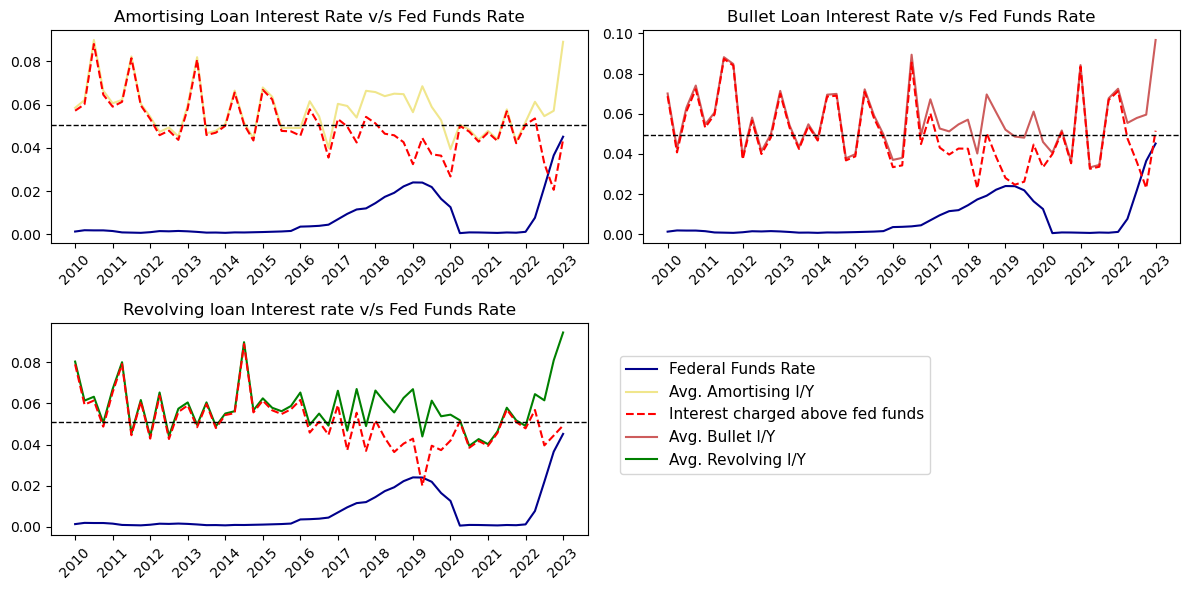

 avg_amortising_int : 5.7544%
 avg_bullet_int : 5.6768%
 avg_revolving_int : 5.8225%

 Average Interest Rate Charged Above the Fed Funds for Amortising Loan : 5.0449%
 Average Interest Rate Charged Above the Fed Funds for Bullet Loan : 4.9673%
 Average Interest Rate Charged Above the Fed Funds for Revolving Loan : 5.1130%


In [29]:
temp = forecasting_data.copy()
forecasting_data["Sanction_Quarter_Group"] = forecasting_data["Sanction_Date"].dt.to_period("Q")
#mev = pd.read_excel("C:/Users/Arsh Sadh/Desktop/Models/Project_4_IFRS9/Sample_Portfolio.xlsm",sheet_name = "Macroeconomic variable")
# fed_funds_rate = pd.read_excel("C:/Users/Arsh Sadh/Downloads/FEDFUNDS.xlsx", sheet_name = "Sheet1")

average_vals = pd.DataFrame(forecasting_data.groupby(["Sanction_Quarter_Group","Type_of_Loan"])["Origination_Interest_Rate"].mean()).reset_index()

average_vals_amortising = average_vals[average_vals["Type_of_Loan"]=="Amortising"].reset_index(drop=True)
gap_amortising = average_vals_amortising["Origination_Interest_Rate"] - fed_funds_rate["FEDFUNDS"]
avg_gap_amortising = gap_amortising.mean()

average_vals_bullet = average_vals[average_vals["Type_of_Loan"]=="Bullet"].reset_index(drop=True)
gap_bullet = average_vals_bullet["Origination_Interest_Rate"] - fed_funds_rate["FEDFUNDS"]
avg_gap_bullet = gap_bullet.mean()

average_vals_revolving = average_vals[average_vals["Type_of_Loan"]=="Revolving"].reset_index(drop=True)
gap_revolving = average_vals_revolving["Origination_Interest_Rate"] - fed_funds_rate["FEDFUNDS"]
avg_gap_revolving = gap_revolving.mean()

fig, ax = plt.subplots(nrows=2,ncols=2,figsize=(12,6))

ax[0,0].plot(fed_funds_rate["FEDFUNDS"], label="Federal Funds Rate", color="darkblue")
ax[0,0].plot(average_vals_amortising["Sanction_Quarter_Group"].astype(str), average_vals_amortising["Origination_Interest_Rate"],
             label="Avg. Amortising I/Y", color="Khaki")

ax[0,0].plot(gap_amortising, color="red", linestyle="--", label="Interest charged above fed funds")
ax[0,0].axhline(y = avg_gap_amortising, linestyle="--", color="black", lw=1)

ax[0,0].set_title("Amortising Loan Interest Rate v/s Fed Funds Rate")

ax[0,1].plot(average_vals_bullet["Sanction_Quarter_Group"].astype(str), average_vals_bullet["Origination_Interest_Rate"],
             label="Avg. Bullet I/Y", color="Indianred")

ax[0,1].plot(fed_funds_rate["FEDFUNDS"],color="darkblue")
ax[0,1].plot(gap_bullet, color="red", linestyle="--")
ax[0,1].axhline(y = avg_gap_bullet, linestyle="--", color="black", lw=1)
ax[0,1].set_title("Bullet Loan Interest Rate v/s Fed Funds Rate")

ax[1,0].plot(average_vals_revolving["Sanction_Quarter_Group"].astype(str), average_vals_revolving["Origination_Interest_Rate"],
             label="Avg. Revolving I/Y", color="green")

ax[1,0].plot(fed_funds_rate["FEDFUNDS"], color="darkblue")
ax[1,0].plot(gap_revolving, color="red", linestyle="--")
ax[1,0].axhline(y = avg_gap_revolving, linestyle="--", color="black", lw=1)
ax[1,0].set_title("Revolving loan Interest rate v/s Fed Funds Rate")

ax[1,1].set_visible(False)


# Setting the x axis values (showing years and not quarters)
quarters = average_vals_amortising["Sanction_Quarter_Group"].astype(str).tolist()
years = [q.split("Q")[0] for q in quarters]
unique_years = sorted(list(set(years)))
tick_indices = [years.index(y) for y in unique_years]

for current_ax in [ax[0,0], ax[0,1], ax[1,0]]:
    current_ax.set_xticks(tick_indices)
    current_ax.set_xticklabels(unique_years, fontsize=10,rotation=45)

fig.legend(loc="center", bbox_to_anchor=(0.65,0.3), fontsize=11)
plt.tight_layout()
plt.show()

avg_amortising_int = average_vals_amortising["Origination_Interest_Rate"].mean()
avg_bullet_int = average_vals_bullet["Origination_Interest_Rate"].mean()
avg_revolving_int = average_vals_revolving["Origination_Interest_Rate"].mean()

print(f" avg_amortising_int : {avg_amortising_int*100:.4f}%\n"
      f" avg_bullet_int : {avg_bullet_int*100:.4f}%\n"
      f" avg_revolving_int : {avg_revolving_int*100:.4f}%\n")

print(f" Average Interest Rate Charged Above the Fed Funds for Amortising Loan : {avg_gap_amortising*100:.4f}%\n"
      f" Average Interest Rate Charged Above the Fed Funds for Bullet Loan : {avg_gap_bullet*100:.4f}%\n"
      f" Average Interest Rate Charged Above the Fed Funds for Revolving Loan : {avg_gap_revolving*100:.4f}%")


## Rating Migration Diagram :

In [30]:
def credit_migration_diagram(reporting_date="2023-03-31",scenario="Base"):
    
    rating_order = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "D"]
    segment_order = ["Commercial","Corporate", "Retail", "SME"]
    
    label = rating_order + segment_order + rating_order
    
    seg_data = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
    df1= seg_data.groupby(["Origination_Rating","Segment"])["Customer_ID"].count().reset_index()
    df1["Origination_Rating"] = pd.Categorical(df1["Origination_Rating"], categories = rating_order, ordered = True)
    df1 = df1.sort_values(by=["Origination_Rating","Segment"]).reset_index(drop=True)
    
    total = df1["Customer_ID"].sum() # Total number of Customers
    
    df1.columns = ["source","target","value"]
    df1["source"] = df1["source"].astype(str)
    df1["source"] = df1["source"] + "(Sanct.)" # S for Sanction Rating
    
    col_name = "Estimated_Rating_"+ scenario
    
    df2 = seg_data.groupby(["Segment",col_name])["Customer_ID"].count().reset_index()
    df2[col_name] = pd.Categorical(df2[col_name],categories=rating_order,ordered=True)
    df2 = df2.sort_values(by=["Segment", col_name]).reset_index(drop=True)
    
    df2.columns = ["source","target","value"]
    df2["target"] = df2["target"].astype(str)
    
    df2["target"] = df2["target"] + "(Report.)" 
    
    total_2 = df2["value"].sum()
    
    merged_df = pd.concat([df1,df2],axis=0)
    
    unique_source_target =  pd.unique(merged_df[["source","target"]].values.ravel("k"))
    
    mapping_dict = {k:v for v,k in enumerate(unique_source_target)}
    
    merged_df["source"] = merged_df["source"].map(mapping_dict)
    merged_df["target"] = merged_df["target"].map(mapping_dict)

    # used to create a list for links color: 
    reverse_mapping_dict = {k:v for k,v in enumerate(unique_source_target)}
    #print(f" Reverse reverse_mapping_dict : {reverse_mapping_dict}")
    
    merged_df_temp = merged_df.copy()
    merged_df_temp["source_ac"] = merged_df_temp["source"].map(reverse_mapping_dict)
    merged_df_temp["target_ac"] = merged_df_temp["target"].map(reverse_mapping_dict)
    #display(merged_df_temp)
    
    linkcolorList = np.where(((merged_df_temp["source_ac"]=="AAA(Sanct.)") | (merged_df_temp["source_ac"]=="AA(Sanct.)") | (merged_df_temp["source_ac"]=="A(Sanct.)")|
                             (merged_df_temp["target_ac"]=="AAA(Report.)") | (merged_df_temp["target_ac"]=="AA(Report.)") | (merged_df_temp["target_ac"]=="A(Report.)")),
                             "rgba(144,238,144,0.25)",
                             np.where(((merged_df_temp["source_ac"]=="BBB(Sanct.)") | (merged_df_temp["source_ac"]=="BB(Sanct.)") | (merged_df_temp["source_ac"]=="B(Sanct.)")|
                                      (merged_df_temp["target_ac"]=="BBB(Report.)") | (merged_df_temp["target_ac"]=="BB(Report.)") | (merged_df_temp["target_ac"]=="B(Report.)")),
                                      "rgba(255,215,0,0.20)",
                                      np.where(((merged_df_temp["source_ac"]=="CCC(Sanct.)") | (merged_df_temp["target_ac"]=="CCC(Report.)")),
                                      "rgba(240,128,128,0.25)","rgba(240,128,128,0.50)"))).tolist()
    
    merged_df_dict = merged_df.to_dict(orient="list")
    
    # Node Colors :
    color_map_key = {"AAA(Sanct.)" : "darkgreen", "AA(Sanct.)": "darkgreen", "A(Sanct.)" : "darkgreen",
                     "BBB(Sanct.)" : "gold", "BB(Sanct.)" : "gold", "B(Sanct.)" : "gold",
                     "CCC(Sanct.)" : "indianred", "D(Sanct.)" : "darkred",
                     "Commercial" : "midnightblue", "Corporate" : "midnightblue", "Retail" : "midnightblue", "SME": "midnightblue",
                     "AAA(Report.)" : "darkgreen", "AA(Report.)": "darkgreen", "A(Report.)" : "darkgreen",
                     "BBB(Report.)" : "gold", "BB(Report.)" : "gold", "B(Report.)" : "gold",
                     "CCC(Report.)" : "indianred", "D(Report.)" : "darkred"
                     }
    
    colors_list = pd.Series(unique_source_target).map(color_map_key).tolist()
    
    map_vals = pd.Series(unique_source_target)
    
    colors_list = map_vals.map(color_map_key)

    #print(f" UNIQUE SOURCE TARGET : \n {unique_source_target}")

    clean_labels = [g.removesuffix("(Sanct.)").removesuffix("(Report.)") for g in unique_source_target]
    
    #Sankey Plotting : 
    fig = go.Figure(data=[go.Sankey(
        arrangement="snap",
        node = dict(
            pad = 15,
            thickness = 20,
            line = dict(color="black", width = 0.5),
            label = clean_labels, #unique_source_target,
            x=[0.01, 0.01, 0.01, 0.01, 0.01, 0.01,0.01,           # 7 sanction rating AAA - CCC
               0.50, 0.50, 0.50, 0.50,                            # 4 segments 'Commercial', 'Corporate', 'Retail', 'SME'
               0.99, 0.99, 0.99, 0.99, 0.99, 0.99, 0.99, 0.99],  # 8 reporting ratings AAA - D
            
            y=[0.01, 0.07, 0.18, 0.42, 0.7, 0.85, 0.95,          # 7 sanction rating AAA - CCC
               0.05, 0.20, 0.55, 0.9,                            # 4 segments 'Commercial', 'Corporate', 'Retail', 'SME'
               0.06, 0.12, 0.01, 0.4, 0.5, 0.25, 0.6,0.85],      # 8 reporting ratings AAA - D
            color = colors_list),
        link = dict(
            source = merged_df_dict["source"],
            target=merged_df_dict["target"],
            value = merged_df_dict["value"],
            color = linkcolorList))],
                   )
    
    fig.update_layout(
        title_text=f"Portfolio Credit rating Migration as on {reporting_date} for {col_name.removeprefix('Estimated_Rating_')} Scenario", 
        font_size=12,width=1150,height=790)
    fig.write_html(f"sankey_diagram_{scenario}_Scenario_{reporting_date}.html")
    #fig.write_image(f"sankey_diagram_{scenario}_Scenario_{reporting_date}.png", width=1200, height=800, scale=2)

    fig.show()
    console.print(f" Total Customers as on {reporting_date} : {total}",style="Bold")
    
scen = ["Base", "Optimistic","Pessimistic"]

widgets.interact(
    credit_migration_diagram, 
    reporting_date=widgets.Select(
        options=reporting_dates_list,
        description='Reporting Date',
        style={'description_width': 'initial'}
    ),
    scenario = widgets.ToggleButtons(
        options=scen,
        description="Scenario",
        button_style="info"
    ))

interactive(children=(Select(description='Reporting Date', options=('2023-03-31', '2023-06-30', '2023-09-30', …

<function __main__.credit_migration_diagram(reporting_date='2023-03-31', scenario='Base')>

# Stage Migration : 

In [31]:
def stage_migration(start_reporting_date = "2023-03-31",reporting_date="2023-06-30",scenario="Base"):

    segment_order = ["Commercial","Corporate", "Retail", "SME"]
    
    stage_order = [1,2,3]
    stage_dict = {s: "S"+str(s) for s,v in enumerate(stage_order,start=1)}
    
    stages = ["S"+str(s) for s in stage_order] # Creates a list : [S1,S2,S3]
    
    # The Source DataFrame :
    df1 = forecasting_data[forecasting_data["Reporting_Date"]==start_reporting_date]
    start_countCust = df1["Customer_ID"].nunique()
    df1 = df1.filter(regex=f"Customer_ID|Segment|Stage_{scenario}")
    df1 = df1.groupby([f"Stage_{scenario}","Segment"])["Customer_ID"].count().reset_index()
    df1.columns= ["source","target","value"]
    
    df1["source"] = df1["source"].map(stage_dict)
    df1["source"] = df1["source"] +"_B"
    
    # The Destination DataFrame :
    df2 = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
    end_countCust = df2["Customer_ID"].nunique()
    df2 = df2.filter(regex=f"Customer_ID|Segment|Stage_{scenario}")
    df2 = df2.groupby(["Segment",f"Stage_{scenario}"])["Customer_ID"].count().reset_index()
    df2.columns = ["source","target","value"]
    df2["target"] = df2["target"].map(stage_dict)
    df2["target"] = df2["target"] +"_F"
    
    
    # Creating a New DataFrame Combining the 2 dataframe created above : 
    
    combinedf = pd.concat([df1,df2],axis=0)
    
    # Now, what we want is for all "Source" and "target" variables to have numbers, which is what plotly requires.
    # We want the unique values to be unique.
    
    unqiue_soure_target = list(pd.unique(combinedf[["source","target"]].values.ravel("k")))
    unqiue_soure_target
    
    mapping_dict  = {k:v for v, k in enumerate(unqiue_soure_target)}
    # Personal note -  Output : {'S1': 0, 'S2': 1, 'S3': 2,'Commercial': 3, 'Corporate': 4, 'Retail': 5, 'SME': 6}
    
    combinedf["source"] = combinedf["source"].map(mapping_dict)
    combinedf["target"] = combinedf["target"].map(mapping_dict)
    
    # Now, we have to modify the dataframe into a Dictionary where every column name is a Key and every value inside that column is a list. 
    combinedf_dict = combinedf.to_dict(orient="list")
    
    # The Alluvial Diagram / Sankey Diagram : 
    # Defining the labels :
    label = stages + segment_order+ stages

    stage_color_map = {
    "S1": "rgba(0, 100, 0, 0.4)",       # Dark Green with 40% transparency
    "S2": "rgba(255, 215, 0, 0.4)",     # Gold with 40% transparency
    "S3": "rgba(205, 92, 92, 0.4)"      # Indian Red with 40% transparency
    }
    
    colorlist = []
    colorlist = np.where((combinedf["source"] == 0) | (combinedf["target"]==7),
                                  "rgba(144, 238, 144, 0.25)",
                                  np.where((combinedf["source"] == 1) | (combinedf["target"]==8),
                                  "rgba(255, 215, 0, 0.25)","rgba(240, 128, 128, 0.25)")).tolist()
    
    clean_labels = [g.removesuffix("_B").removesuffix("_F") for g in unqiue_soure_target]
    
    fig = go.Figure(data = [go.Sankey(
        arrangement="snap",
        node = dict(
            thickness=20,line = dict(color="black", width=0.5),
            label= clean_labels, # unqiue_soure_target,
            color=["darkgreen","gold","indianred","midnightblue","midnightblue","midnightblue","midnightblue","darkgreen","gold","indianred"]
            ),
        link = dict(
            source= combinedf_dict["source"], # The Dictionary we created from out DataFrame
            target=combinedf_dict["target"],
            value = combinedf_dict["value"],
            color=colorlist
        ))])
    fig.update_layout(
            title_text=f"Portfolio Stage Migration between {start_reporting_date} and {reporting_date} under {scenario} Scenario", 
            font_size=12,width=1150,height=790)
    fig.show()
    
    console.print(f"Total Customers on {start_reporting_date} : {start_countCust}\n"
                  f"Total Customers on {reporting_date} : {end_countCust}")
    #display(mapping_dict)
    #display(combinedf)
    
start_reporting_date_widget = widgets.Select(options=reporting_dates_list,description="Start Date", style={"description_width":"initial"})
reporting_date_widget = widgets.Select(options=reporting_dates_list,value=reporting_dates_list[1],description="End Date", style={"description_width":"initial"})
scenario_widget = widgets.ToggleButtons(options=scen,description="Scenario",button_style="Info")

ui_interact = widgets.interactive(stage_migration,
                                   start_reporting_date = start_reporting_date_widget,
                                   reporting_date = reporting_date_widget,
                                   scenario = scenario_widget
                                  )
dates_hbox = widgets.HBox([start_reporting_date_widget,reporting_date_widget])
final_layout = widgets.VBox([dates_hbox, scenario_widget, ui_interact.children[-1]])

display(final_layout)

# Sector - Stage Migration - A granular look in the portfolio

In [32]:
def stage_sector_migration(start_reporting_date = "2023-03-31",reporting_date="2023-06-30",scenario="Base", segment="Retail"):

    sector_order = forecasting_data[forecasting_data["Segment"]==segment]["Sector"].unique().tolist()
    stage_order = [1,2,3]
    stage_dict = {s: "S"+str(s) for s,v in enumerate(stage_order,start=1)}
    
    stages = ["S"+str(s) for s in stage_order] # Creates a list : [S1,S2,S3]
    
    # The Source DataFrame :
    df1 = forecasting_data[(forecasting_data["Reporting_Date"]==start_reporting_date) & (forecasting_data["Segment"]==segment)]
    start_countCust = df1["Customer_ID"].nunique()
    df1 = df1.filter(regex=f"Customer_ID|Sector|Stage_{scenario}")
    df1 = df1.groupby([f"Stage_{scenario}","Sector"])["Customer_ID"].count().reset_index()
    df1.columns= ["source","target","value"]
    
    df1["source"] = df1["source"].map(stage_dict)
    df1["source"] = df1["source"] +"_B"
    
    
    # The Destination DataFrame :
    df2 = forecasting_data[(forecasting_data["Reporting_Date"]==reporting_date) & (forecasting_data["Segment"]==segment)]
    end_countCust = df2["Customer_ID"].nunique()
    df2 = df2.filter(regex=f"Customer_ID|Sector|Stage_{scenario}")
    df2 = df2.groupby(["Sector",f"Stage_{scenario}"])["Customer_ID"].count().reset_index()
    df2.columns = ["source","target","value"]
    df2["target"] = df2["target"].map(stage_dict)
    df2["target"] = df2["target"] +"_F"
     
    # # Creating a New DataFrame Combining the 2 dataframe created above : 
    
    combinedf = pd.concat([df1,df2],axis=0)
    
    # # Now, what we want is for all "Source" and "target" variables to have numbers, which is what plotly requires.
    # # We want the unique values to be unique.
    
    unqiue_source_target = list(pd.unique(combinedf[["source","target"]].values.ravel("k")))
    
    mapping_dict  = {k:v for v, k in enumerate(unqiue_source_target)}
    # Personal note -  Output : {'S1_B': 0,'S2_B': 1, 'S3_B': 2, 'Logistics': 3, 'Real Estate': 4, 'Retail Trade': 5, 'Wholesale': 6, 'S1_F': 7, 'S2_F': 8, 'S3_F': 9}
    
    combinedf["source"] = combinedf["source"].map(mapping_dict)
    combinedf["target"] = combinedf["target"].map(mapping_dict)
    
    # # Now, we have to modify the dataframe into a Dictionary where every column name is a Key and every value inside that column is a list. 
    combinedf_dict = combinedf.to_dict(orient="list")
    
    # # The Alluvial Diagram / Sankey Diagram : 
    # # Defining the labels :
    label = stages + sector_order + stages

    # used to create a list for links color: 
    reverse_mapping_dict = {k:v for k,v in enumerate(unqiue_source_target)}
    #print(f" Reverse reverse_mapping_dict : {reverse_mapping_dict}")
    
    combinedf_temp = combinedf.copy()
    combinedf_temp["source_ac"] = combinedf_temp["source"].map(reverse_mapping_dict)
    combinedf_temp["target_ac"] = combinedf_temp["target"].map(reverse_mapping_dict)

    colorlist = []
    colorlist = np.where((combinedf_temp["source_ac"] == "S1_B") | (combinedf_temp["target_ac"]=="S1_F"),
                                  "rgba(144, 238, 144, 0.25)",
                                  np.where((combinedf_temp["source_ac"] == "S2_B") | (combinedf_temp["target_ac"]=="S2_F"),
                                  "rgba(255, 215, 0, 0.25)","rgba(240, 128, 128, 0.25)")).tolist()
    
    clean_labels = [g.removesuffix("_B").removesuffix("_F") for g in unqiue_source_target]

    node_colorList = ["darkgreen","gold","indianred"]+ ["midnightblue"]*len(sector_order)+["darkgreen","gold","indianred"]
    
    fig = go.Figure(data = [go.Sankey(
        arrangement="snap",
        node = dict(
            thickness=20,line = dict(color="black", width=0.5),
            label= clean_labels, # unqiue_soure_target,
            color=node_colorList
            ),
        link = dict(
            source= combinedf_dict["source"], # The Dictionary we created from out DataFrame
            target=combinedf_dict["target"],
            value = combinedf_dict["value"],
            color=colorlist
        ))])
    fig.update_layout(
            title_text=f"Portfolio Stage Migration within the {segment} Segment between {start_reporting_date} and {reporting_date} under {scenario} Scenario", 
            font_size=12,width=1150,height=790)
    fig.show()
    
    console.print(f"Total Customers on {start_reporting_date} : {start_countCust}\n"
                  f"Total Customers on {reporting_date} : {end_countCust}")

segments = forecasting_data["Segment"].unique().tolist()

start_reporting_date_widget = widgets.Select(options=reporting_dates_list,description="Start Date", style={"description_width":"initial"})
reporting_date_widget = widgets.Select(options=reporting_dates_list,value=reporting_dates_list[1],description="End Date", style={"description_width":"initial"})
scenario_widget = widgets.ToggleButtons(options=scen,description="Scenario",button_style="Info")
Segment_widget = widgets.ToggleButtons(options=segments,description="Segment",button_style="Info")

ui_interact = widgets.interactive(stage_sector_migration,
                               start_reporting_date = start_reporting_date_widget,
                               reporting_date = reporting_date_widget,
                               scenario = scenario_widget,
                               segment=Segment_widget
                              )
dates_hbox = widgets.HBox([start_reporting_date_widget,reporting_date_widget])
final_layout = widgets.VBox([dates_hbox, scenario_widget,Segment_widget, ui_interact.children[-1]])
display(final_layout)

In [33]:
def rating_heatmap(reporting_date = "2023-03-31",scenario="Base"):
    
    scen = "Estimated_Rating_"+scenario
    
    seg_data = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
    
    df3 = (seg_data.groupby(["Sector", scen])["Customer_ID"].count().reset_index().rename(columns={"Customer_ID": "Count"}))
    
    heatmap_data = df3.pivot(index="Sector", columns=scen, values="Count").fillna(0)
    
    rating_order = ["AAA","AA","A","BBB","BB","B","CCC","D"]
    heatmap_data = heatmap_data.reindex(columns=rating_order)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    sns.heatmap(heatmap_data,annot=True,fmt=".0f",cmap="YlOrRd",linewidths=0.5,ax=ax)
    
    ax.set_title(f"Loan Count by Sector and Reported Rating : {reporting_date}", fontsize=12)
    ax.set_xlabel("Estimated Rating")
    ax.set_ylabel("Sector")
    plt.tight_layout()
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    plt.show()

widgets.interact(rating_heatmap,
                 reporting_date = widgets.Select(options=reporting_dates_list, description="Reporting Date",style={"description_width":"initial"}),
                 scenario=widgets.ToggleButtons(options=scen, description="Scenario",button_style="info",style={"description_width":"initial"})
                )

interactive(children=(Select(description='Reporting Date', options=('2023-03-31', '2023-06-30', '2023-09-30', …

<function __main__.rating_heatmap(reporting_date='2023-03-31', scenario='Base')>

In [34]:
def cluster_heatmap(reporting_date="2023-03-31",scenario="Base"):
    
    scen = "Estimated_Rating_"+ scenario
    seg_data = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
    
    df_3 = (seg_data.groupby(["Sector", scen])["Customer_ID"].count().reset_index().rename(columns={"Customer_ID": "Count"}))
    heatmap_data = df_3.pivot(index="Sector", columns=scen, values="Count").fillna(0)
    sns.clustermap(heatmap_data,cmap="YlOrRd",annot=True, fmt=".0f", figsize=(15,10))

widgets.interact(cluster_heatmap, reporting_date = widgets.Select(options=reporting_dates_list, description="Reporting Date", style={"description_width":"initial"}),
                                  scenario=widgets.ToggleButtons(options=scen, description="Scenario", button_style="info",style={"description_width":"initial"})
                )

interactive(children=(Select(description='Reporting Date', options=('2023-03-31', '2023-06-30', '2023-09-30', …

<function __main__.cluster_heatmap(reporting_date='2023-03-31', scenario='Base')>

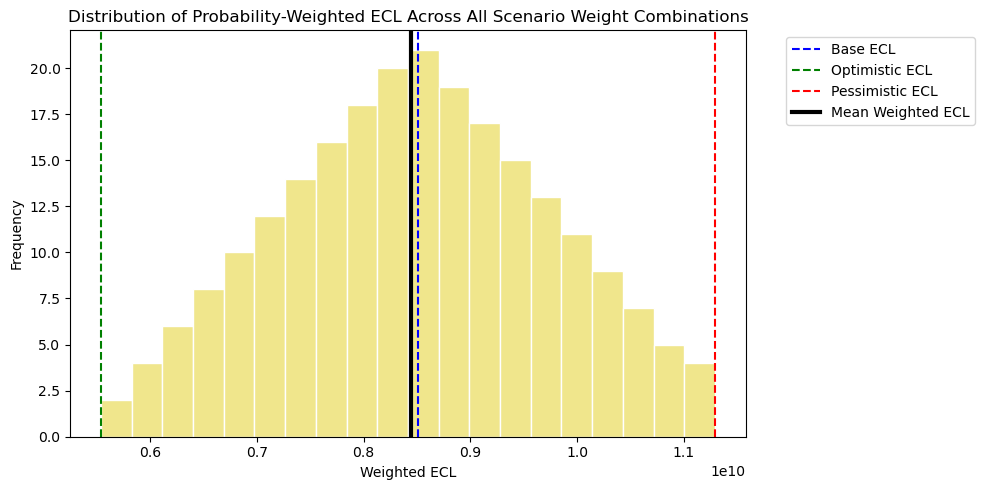

In [35]:
# Plot of ECL for each weights : 

from itertools import product

# ECL values per scenario

ECL_comp = forecasting_data[forecasting_data["Reporting_Date"]==reporting_date]
ECL_base_val  = ECL_comp["ECL_Base"].sum()
ECL_optimistic_val = ECL_comp["ECL_Optimistic"].sum()
ECL_pessimistic_val = ECL_comp["ECL_Pessimistic"].sum()

step = 0.05

weights = [(wb, wo, wp) for wb, wo, wp in product(np.arange(0, 1 + step, step), repeat=3) if abs(wb + wo + wp - 1.0) < 1e-09]

results = pd.DataFrame(weights, columns=["w_base", "w_opt", "w_pess"])
results["Weighted_ECL"] = ((results["w_base"] * ECL_base_val) + (results["w_opt"] * ECL_optimistic_val) + (results["w_pess"] * ECL_pessimistic_val))

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(results["Weighted_ECL"],bins= 20, color="khaki",edgecolor="white")
ax.axvline(ECL_base_val,        color="blue",  linestyle="--", label=f"Base ECL")
ax.axvline(ECL_optimistic_val,  color="green", linestyle="--", label=f"Optimistic ECL")
ax.axvline(ECL_pessimistic_val, color="red",   linestyle="--", label=f"Pessimistic ECL")
ax.axvline(results["Weighted_ECL"].mean(), color="black", linestyle="-", lw=3, label="Mean Weighted ECL")

ax.set_xlabel("Weighted ECL")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Probability-Weighted ECL Across All Scenario Weight Combinations")
ax.legend(bbox_to_anchor=(1.05,1))
plt.tight_layout()